# InGesture: Dataset Visualization for TF-C + DINOv3

Notebook trực quan hóa dữ liệu gia tốc X/Y/Z cho tám cử chỉ. Đây là dữ liệu
**InGesture công khai**, không phải bộ dữ liệu tự thu thập.

Dataset dùng trên Kaggle: [Gesture Dataset của dự án](https://www.kaggle.com/datasets/nguyntinmnh41/gesture-dataset).

Nguồn: [InGesture v5, DOI 10.17632/fdxst56tcj.5](https://doi.org/10.17632/fdxst56tcj.5),
giấy phép CC BY 4.0. Cảm biến IMU đeo cổ tay; tần số danh định khoảng 200 Hz.

**Chạy trên Kaggle:** tạo Notebook, chọn Add Input và gắn dataset InGesture có
thư mục `subject_*`. Nếu input là ZIP chưa được Kaggle giải nén, cần giải nén
trước vào `/kaggle/working` rồi chỉnh `DATA_ROOT`. Không cần GPU hoặc trọng số AI.
Các biểu đồ dưới đây chỉ được tạo từ file thật, không có dữ liệu mô phỏng.

### Câu hỏi khám phá
1. Dữ liệu có mất cân bằng lớp hay thiếu người/cử chỉ không?
2. Thời lượng, dữ liệu thiếu và số cửa sổ sau xử lý ra sao?
3. Tín hiệu time/frequency và ảnh đầu vào DINOv3 có đặc điểm gì?
4. Cách chia subject và chuẩn hóa có ngăn rò rỉ dữ liệu không?

### Đặc điểm dataset

| Thuộc tính | Giá trị / cách kiểm chứng |
|---|---|
| Đơn vị dữ liệu gốc | Một segmented CSV, một nhãn cử chỉ ở mức recording |
| Kênh dùng trong dự án | Gia tốc X/Y/Z; các kênh gyro trong CSV không dùng cho mô hình hiện tại |
| Số người | 50; kiểm tra lại từ toàn bộ inventory |
| Nhãn | 8 lớp, giữ nguyên định nghĩa của InGesture |
| Tần số | Khoảng 200 Hz danh định; không đo lại từ timestamp |
| Đầu vào TF-C | `[3, 206]`, stride 103 |
| Tái lập hình minh họa | Seed 42, tối đa 12 người train khác nhau mỗi lớp |

### Cách tổ chức học từ notebook tham khảo

Tham khảo [Sentinel-2 RPG - Dataset Visualization](https://www.kaggle.com/code/loanhviet/sentinel-2-rpg-dataset-visualization)
về trình tự: giới thiệu → inventory/format → mẫu thật và nhãn → biến thiên
thời gian/nhóm → thống kê toàn bộ dataset → kết luận. Các mục ảnh vệ tinh,
mask và vùng địa lý được chuyển thành tín hiệu, nhãn recording và subject.
Toàn bộ code, hình và nhận xét InGesture trong notebook này được xây dựng
từ dữ liệu của dự án; không sao chép kết quả của dataset tham khảo.

Tham khảo bổ sung [Sensor Logger: Five-Gesture Dataset Visualization](https://www.kaggle.com/code/vuvandat000099/sensor-logger-five-gesture-dataset-visualization)
về PCA đặc trưng thống kê, RMS kênh, STFT và kiểm tra trùng. Phiên bản InGesture
vẫn dùng tám lớp và ba kênh gia tốc; số liệu và đồ thị đều được tính lại.

## 0. Setup
Notebook tự chứa các hàm đọc và vẽ; không cần clone GitHub hoặc tải trọng số AI.

In [1]:
"""Reproducible EDA of raw InGesture; never requires model weights or torch."""
from pathlib import Path
import argparse
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

CLASSES = ['other', 'fluid_intake', 'answering_cell_phone', 'scratching_head',
           'passing_hand_over_face', 'adjusting_glasses_touching_temples',
           'holding_chin', 'stretching_with_hands_behind_neck']
NAMES = ['Other', 'Fluid intake', 'Answer phone', 'Scratch head', 'Hand over face',
         'Adjust glasses', 'Hold chin', 'Stretch neck']
COLORS = ['#2563eb', '#f59e0b', '#14b8a6']


def find_root(base):
    """Detect raw subject folders, including nested Kaggle ZIP extraction."""
    base = Path(base)
    candidates = [base, *sorted(base.rglob('subject_1'))]
    for candidate in candidates:
        root = candidate.parent if candidate.name == 'subject_1' else candidate
        if next(root.glob('subject_*/*__*.csv'), None) is not None:
            return root
    raise FileNotFoundError('Attach/extract InGesture containing subject_*/*__*.csv')


def inventory(root, metadata):
    rows, previews, train_points = [], {}, []
    subject_split = {s: split for key, split in [('train_subjects', 'train'),
                     ('validation_subjects', 'validation'), ('test_subjects', 'test')]
                     for s in metadata[key]}
    rng = np.random.default_rng(42)
    for path in sorted(Path(root).glob('subject_*/*__*.csv')):
        gesture = path.stem.split('__', 1)[0]
        if gesture not in CLASSES:
            continue
        subject = path.parent.name
        if subject not in subject_split:
            raise ValueError(f'Unknown subject {subject}; use matching metadata.json')
        frame = pd.read_csv(path, usecols=['x', 'y', 'z']).apply(pd.to_numeric, errors='coerce')
        frame = frame.replace([np.inf, -np.inf], np.nan)
        missing = int(frame.isna().sum().sum())
        clean = frame.interpolate(limit_direction='both').dropna().to_numpy(dtype=np.float32)
        split = subject_split[subject]
        windows = max(0, 1 + (len(clean) - metadata['window_size']) // metadata['stride'])
        rows.append(dict(file=str(path.relative_to(root)).replace('\\', '/'),
                         subject=subject, gesture=gesture, split=split,
                         raw_samples=len(frame), clean_samples=len(clean),
                         nonfinite_cells=missing, windows=windows,
                         recording_hash=hashlib.sha256(clean.tobytes()).hexdigest(),
                         constant_recording=bool(len(clean) and np.all(np.ptp(clean,axis=0)<1e-8)),
                         seconds=len(clean) / metadata['sampling_rate_hz']))
        if split == 'train' and len(clean):
            chosen = rng.choice(len(clean), min(50, len(clean)), replace=False)
            train_points.append(clean[chosen])
            if gesture not in previews and len(clean) >= metadata['window_size']:
                previews[gesture] = clean[:min(1200, len(clean))]
    if not rows or set(previews) != set(CLASSES):
        raise ValueError('Need nonempty raw data and a training example for each of 8 classes')
    return pd.DataFrame(rows), previews, np.concatenate(train_points)


def save(fig, output, name):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    fig.savefig(output / name, dpi=160, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    return output / name


def class_distribution(frame, metadata, output):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
    for ax, field, title in zip(axes, ['file', 'windows'], ['Recordings per gesture', 'Overlapping windows per gesture']):
        counts = (frame.groupby('gesture').size() if field == 'file' else frame.groupby('gesture').windows.sum()).reindex(CLASSES)
        ax.barh(NAMES, counts, color='#2563eb')
        ax.set_xscale('log'); ax.invert_yaxis(); ax.set_title(title)
        ax.set_xlabel('Count (log scale)')
        for i, value in enumerate(counts): ax.text(value * 1.03, i, f'{value:,}', va='center', fontsize=8)
        ax.set_xlim(0.8, counts.max() * 2)
    return save(fig, output, '01_class_distribution.png')


def split_distribution(frame, metadata, output):
    counts = frame.pivot_table(index='gesture', columns='split', values='windows', aggfunc='sum', fill_value=0).reindex(CLASSES)[['train', 'validation', 'test']]
    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    image = ax.imshow(np.log1p(counts.to_numpy()), cmap='Blues', aspect='auto')
    ax.set_xticks(range(3), counts.columns); ax.set_yticks(range(8), NAMES)
    for i in range(8):
        for j in range(3): ax.text(j, i, f'{counts.iloc[i,j]:,}', ha='center', va='center', color='black', bbox=dict(facecolor='white', alpha=.75, edgecolor='none'))
    ax.set_title('Windows by subject-disjoint split (counts; log color scale)')
    fig.colorbar(image, ax=ax, label='log(1 + window count)')
    return save(fig, output, '02_split_distribution.png')


def subject_coverage(frame, metadata, output):
    counts = pd.crosstab(frame.subject, frame.gesture).reindex(columns=CLASSES, fill_value=0)
    counts = counts.loc[sorted(counts.index, key=lambda x: int(x.split('_')[1]))]
    fig, ax = plt.subplots(figsize=(13, 13), constrained_layout=True)
    image = ax.imshow(counts, cmap='YlGnBu', aspect='auto')
    ax.set_xticks(range(8), NAMES, rotation=35, ha='right')
    ax.set_yticks(range(len(counts)), counts.index, fontsize=7)
    ax.set_title('Recording coverage per subject and gesture')
    fig.colorbar(image, ax=ax, label='Number of segmented recordings')
    return save(fig, output, '03_subject_coverage.png')


def quality(frame, metadata, output):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    axes[0].boxplot([frame.loc[frame.gesture == c, 'seconds'] for c in CLASSES], vert=False, tick_labels=NAMES, showfliers=False)
    axes[0].set_xscale('log'); axes[0].set_xlabel('Seconds, approximated from sample count / nominal Hz')
    axes[0].set_title('Duration by gesture (outliers hidden)')
    values = [frame.nonfinite_cells.sum(), (frame.raw_samples - frame.clean_samples).sum(), (frame.windows == 0).sum()]
    axes[1].bar(['Nonfinite\ncells', 'Dropped\nrows', 'Files shorter\nthan window'], values, color=['#f59e0b', '#ef4444', '#64748b'])
    for i, v in enumerate(values): axes[1].text(i, v, f'{int(v):,}', ha='center', va='bottom')
    axes[1].set_ylim(0, max(1, max(values) * 1.25)); axes[1].set_title('Data quality audit (different units)')
    return save(fig, output, '04_quality_duration.png')


def signal_examples(previews, metadata, output, frequency=False):
    fig, axes = plt.subplots(4, 2, figsize=(15, 12), constrained_layout=True)
    hz = metadata['sampling_rate_hz']
    for ax, gesture, name in zip(axes.flat, CLASSES, NAMES):
        values = previews[gesture]
        if frequency:
            centered = values - values.mean(axis=0)
            spectrum = np.abs(np.fft.rfft(centered * np.hanning(len(values))[:, None], axis=0)) / len(values)
            domain = np.fft.rfftfreq(len(values), d=1/hz)
            for k in range(3): ax.plot(domain, spectrum[:, k], color=COLORS[k], label='XYZ'[k], lw=1)
            ax.set_xlim(0, 30); ax.set_xlabel('Hz (nominal sample rate)'); ax.set_ylabel('Windowed |FFT| / N')
        else:
            for k in range(3): ax.plot(np.arange(len(values))/hz, values[:, k], color=COLORS[k], label='XYZ'[k], lw=.9)
            ax.set_xlabel('Seconds (nominal sample rate)'); ax.set_ylabel('Acceleration (g)')
        ax.set_title(name + ' — one training recording'); ax.legend(loc='upper right', ncol=3, fontsize=7)
    return save(fig, output, '06_frequency_examples.png' if frequency else '05_time_examples.png')


def train_statistics(points, metadata, output):
    stats = metadata['normalization']
    normalized = (np.clip(points, stats['clip_low'], stats['clip_high']) - stats['mean']) / stats['std']
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for k in range(3):
        axes[0].hist(points[:,k], bins=70, density=True, histtype='step', color=COLORS[k], label='XYZ'[k])
        axes[1].hist(normalized[:,k], bins=70, density=True, histtype='step', color=COLORS[k], label='XYZ'[k])
    axes[0].set(title='Raw sampled training points', xlabel='Acceleration (g)', ylabel='Density')
    axes[1].set(title='After train-only normalization', xlabel='Standardized acceleration', ylabel='Density')
    for ax in axes[:2]: ax.legend()
    corr = np.corrcoef(points.T)
    axes[2].imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
    axes[2].set_xticks(range(3), list('XYZ')); axes[2].set_yticks(range(3), list('XYZ'))
    axes[2].set_title('Axis correlation (sampled train)')
    for i in range(3):
        for j in range(3): axes[2].text(j,i,f'{corr[i,j]:.2f}',ha='center',va='center')
    return save(fig, output, '07_train_statistics.png')


def adapter_examples(previews, metadata, output):
    """Initial identity-channel adapter, not learned model output."""
    fig, axes = plt.subplots(2, 8, figsize=(17, 5), constrained_layout=True)
    stats = metadata['normalization']
    for col, gesture in enumerate(CLASSES):
        values = previews[gesture][:metadata['window_size']]
        values = ((np.clip(values, stats['clip_low'], stats['clip_high']) - stats['mean']) / stats['std']).T
        for row, signal in enumerate([values, np.log1p(np.abs(np.fft.fft(values, axis=-1)))]):
            signal = (signal - signal.mean(axis=-1, keepdims=True)) / np.maximum(signal.std(axis=-1, keepdims=True), 1e-6)
            # PyTorch interpolate align_corners=False uses these source centers.
            centers = np.clip((np.arange(64) + .5) * signal.shape[-1] / 64 - .5, 0, signal.shape[-1]-1)
            rgb = np.stack([np.interp(centers, np.arange(len(trace)), trace) for trace in signal])
            rgb = (np.tanh(rgb / 3) + 1) / 2
            image = np.repeat(rgb.T[None, :, :], 64, axis=0)
            axes[row,col].imshow(image); axes[row,col].set_xticks([]); axes[row,col].set_yticks([])
            if row == 0: axes[row,col].set_title(NAMES[col], fontsize=8)
    axes[0,0].set_ylabel('Time'); axes[1,0].set_ylabel('Frequency')
    fig.suptitle('Initial signal-to-RGB adapter (before image normalization; not learned output)')
    return save(fig, output, '08_adapter_examples.png')


def validate_counts(frame, metadata):
    for split, key in [('train', 'train'), ('validation', 'validation'), ('test', 'test')]:
        actual = frame[frame.split == split].groupby('gesture').windows.sum().reindex(CLASSES, fill_value=0)
        expected = metadata[key + '_windows_by_class']
        if any(int(actual[c]) != expected[c] for c in CLASSES):
            raise ValueError(f'{split} counts differ from preprocessing metadata')


def sample_pool(root, frame, metadata, per_class=12, seed=42):
    """One seeded recording per training subject, up to per_class subjects.

    All paired figures use this same pool. Global counts still use the full
    inventory. Selection is independent of model predictions or signal shape.
    """
    rng, pool, manifest = np.random.default_rng(seed), {}, []
    for gesture in CLASSES:
        available = frame[(frame.split == 'train') & (frame.gesture == gesture) & (frame.windows > 0)]
        subjects = np.array(sorted(available.subject.unique()))
        chosen_subjects = rng.choice(subjects, min(per_class, len(subjects)), replace=False)
        pool[gesture] = []
        for subject in chosen_subjects:
            paths = sorted(available.loc[available.subject == subject, 'file'])
            relative = paths[int(rng.integers(len(paths)))]
            raw = pd.read_csv(Path(root)/relative, usecols=['x','y','z'])
            values = raw.apply(pd.to_numeric, errors='coerce').replace([np.inf,-np.inf],np.nan).interpolate(limit_direction='both').dropna().to_numpy(dtype=np.float32)
            if len(values) < metadata['window_size']:
                raise ValueError('Pool file no longer matches inventory: ' + relative)
            pool[gesture].append(dict(file=relative, subject=subject, values=values, gesture=gesture))
            manifest.append(dict(file=relative, subject=subject, gesture=gesture, label_id=CLASSES.index(gesture)))
    return pool, pd.DataFrame(manifest)


def sample_format(root, pool, metadata):
    first = pool[CLASSES[0]][0]
    raw = pd.read_csv(Path(root)/first['file'])
    print('Example file:', first['file'])
    print('Full CSV shape:', raw.shape)
    print('Columns / dtypes:', raw.dtypes.astype(str).to_dict())
    print(raw.head(3).to_string(index=False))
    print('X/Y/Z:', first['values'].shape, first['values'].dtype)
    print('One model window:', first['values'][:metadata['window_size']].T.shape)
    print('Annotation granularity: one file-level label inferred from segmented filename.')
    print('No frame-level onset/offset annotation is inferred or fabricated.')


def label_alignment(pool, metadata, output):
    selected = [1, 3, 5, 7]
    fig, axes = plt.subplots(4, 3, figsize=(16, 12), constrained_layout=True)
    stats = metadata['normalization']
    hz, window = metadata['sampling_rate_hz'], metadata['window_size']
    for row, index in enumerate(selected):
        item = pool[CLASSES[index]][0]
        values = item['values'][:1200]
        domain = np.arange(len(values))/hz
        for k in range(3): axes[row,0].plot(domain, values[:,k], color=COLORS[k], lw=.8, label='XYZ'[k])
        axes[row,0].set_title(f"{NAMES[index]} | {item['subject']}")
        axes[row,0].set_ylabel('Acceleration (g)'); axes[row,0].set_xlabel('Seconds (nominal Hz)')
        axes[row,0].legend(ncol=3, fontsize=7)
        axes[row,1].axvspan(0, domain[-1], color=plt.cm.tab10(index), alpha=.35)
        axes[row,1].text(.5,.5, f'ID {index}: {NAMES[index]}\nFile-level annotation', ha='center', va='center', transform=axes[row,1].transAxes, fontsize=10)
        axes[row,1].set_xlim(0, domain[-1]); axes[row,1].set_ylim(0,1); axes[row,1].set_yticks([])
        axes[row,1].set_xlabel('Seconds (nominal Hz)'); axes[row,1].set_title('Label belongs to the recording')
        normalized = (np.clip(values[:window],stats['clip_low'],stats['clip_high'])-stats['mean'])/stats['std']
        for k in range(3): axes[row,2].plot(np.arange(window),normalized[:,k],color=COLORS[k],lw=.8,label='XYZ'[k])
        axes[row,2].set_title(f'First {window}-sample window | inherited label {index}')
        axes[row,2].set_xlabel('Sample index'); axes[row,2].set_ylabel('Standardized acceleration')
    fig.suptitle('Signal / file-level label / model window — no onset or offset ground truth')
    return save(fig, output, '09_signal_label_alignment.png')


def multisubject_examples(pool, metadata, output):
    fig, axes = plt.subplots(4, 3, figsize=(15, 11), sharey='row', constrained_layout=True)
    for row, index in enumerate([1,3,5,7]):
        for col, item in enumerate(pool[CLASSES[index]][:3]):
            values = item['values'][:1200]
            axes[row,col].plot(np.arange(len(values))/metadata['sampling_rate_hz'],np.linalg.norm(values,axis=1),color='#2563eb',lw=.9)
            axes[row,col].set_title(f"{NAMES[index]} | {item['subject']}")
            axes[row,col].set_xlabel('Seconds (nominal Hz)')
            if col==0: axes[row,col].set_ylabel('Acceleration magnitude (g)')
    fig.suptitle('Same gesture, different training subjects (shared y scale per row)')
    return save(fig, output, '10_multi_subject_examples.png')


def gesture_profiles(pool, metadata, output):
    fig, axes = plt.subplots(4, 2, figsize=(14, 11), constrained_layout=True)
    progress = np.linspace(0, 1, 200)
    for ax, gesture, name in zip(axes.flat,CLASSES,NAMES):
        traces=[]
        for item in pool[gesture]:
            magnitude=np.linalg.norm(item['values'],axis=1)
            traces.append(np.interp(progress,np.linspace(0,1,len(magnitude)),magnitude))
        traces=np.stack(traces); mean,std=traces.mean(axis=0),traces.std(axis=0)
        ax.fill_between(progress*100,mean-std,mean+std,alpha=.2,color='#2563eb',label='±1 SD across recordings')
        ax.plot(progress*100,mean,color='#2563eb',lw=1.5,label='Mean')
        ax.set_title(f'{name} | n={len(traces)} recordings from distinct subjects')
        ax.set_xlabel('Relative progress in recording (%)'); ax.set_ylabel('Magnitude (g)')
        ax.legend(fontsize=7)
    fig.suptitle('Gesture profiles — resampled only for display, not onset-aligned or model input')
    return save(fig, output, '11_gesture_profiles.png')


def pool_features(pool, metadata):
    """One fixed-length normalized window per selected training recording."""
    stats=metadata['normalization']; windows=[]; labels=[]
    for gesture in CLASSES:
        for item in pool[gesture]:
            values=item['values'][:metadata['window_size']]
            values=(np.clip(values,stats['clip_low'],stats['clip_high'])-stats['mean'])/stats['std']
            windows.append(values); labels.append(gesture)
    windows=np.stack(windows)
    features=np.concatenate([windows.mean(axis=1),windows.std(axis=1),
                            np.sqrt(np.mean(windows**2,axis=1)),
                            np.quantile(windows,.95,axis=1)-np.quantile(windows,.05,axis=1)],axis=1)
    return windows,features,np.array(labels)


def pca_features(pool, metadata, output):
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    _,features,labels=pool_features(pool,metadata)
    pca=PCA(n_components=2)
    embedding=pca.fit_transform(StandardScaler().fit_transform(features))
    fig,ax=plt.subplots(figsize=(10,7),constrained_layout=True)
    for index,gesture in enumerate(CLASSES):
        selected=labels==gesture
        ax.scatter(embedding[selected,0],embedding[selected,1],label=NAMES[index],color=plt.cm.tab10(index),s=35,alpha=.7)
    ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})',
           title='PCA of 12 statistical features — selected training windows only')
    ax.legend(fontsize=8)
    return save(fig,output,'12_pca_features.png')


def channel_rms(pool, metadata, output):
    windows,_,labels=pool_features(pool,metadata)
    rms=np.sqrt(np.mean(windows**2,axis=1))
    matrix=np.stack([rms[labels==gesture].mean(axis=0) for gesture in CLASSES])
    fig,ax=plt.subplots(figsize=(9,6),constrained_layout=True)
    image=ax.imshow(matrix,cmap='YlGnBu',aspect='auto')
    ax.set_xticks(range(3),list('XYZ'));ax.set_yticks(range(8),NAMES)
    ax.set_title('Mean channel RMS by gesture — selected normalized training windows')
    for i in range(8):
        for j in range(3):ax.text(j,i,f'{matrix[i,j]:.2f}',ha='center',va='center')
    fig.colorbar(image,ax=ax,label='RMS (standardized units, not physical energy)')
    return save(fig,output,'13_channel_rms.png')


def time_frequency(pool, metadata, output):
    fig,axes=plt.subplots(4,2,figsize=(14,12),constrained_layout=True)
    for ax,gesture,name in zip(axes.flat,CLASSES,NAMES):
        item=pool[gesture][0];values=item['values'][:1200,0]
        ax.specgram(values-values.mean(),NFFT=64,Fs=1.0,noverlap=48,cmap='magma')
        ax.set(title=f"{name} | {item['subject']} | Acceleration X",xlabel='Sample index',ylabel='Frequency (cycles/sample)')
    fig.suptitle('STFT visualization only — not the frequency image used by the deployed model')
    return save(fig,output,'14_time_frequency.png')


def duplicate_audit(frame, metadata, output):
    duplicates=frame[frame.duplicated('recording_hash',keep=False)]
    across=duplicates.groupby('recording_hash').split.nunique()
    report={'scope':'Exact cleaned float32 X/Y/Z recording arrays; not window-level or approximate duplicates',
            'recordings':len(frame),'constant_recordings':int(frame.constant_recording.sum()),
            'duplicate_recordings_after_first':int(frame.duplicated('recording_hash').sum()),
            'unique_hashes_shared_across_subject_splits':int((across>1).sum()),
            'note':'Matching constant signals may occur naturally; inspect provenance before interpreting leakage.'}
    Path(output).mkdir(parents=True,exist_ok=True)
    Path(output,'duplicate_audit.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    duplicates.to_csv(Path(output,'duplicate_recordings.csv'),index=False)
    return report



## 1. Dataset Structure and Inspection — kiểm kê và chia tập

Chỉ dùng segmented CSV có tên `gesture__*.csv` với tám nhãn hợp lệ, tránh đếm
trùng file recording chưa tách. Những người train/validation/test được cố định
theo metadata của pipeline dự án (32/8/10 người); không chia ngẫu nhiên các
cửa sổ chồng lấn. Tất cả ngưỡng clipping, mean/std được fit từ train.
Notebook dùng metadata nhúng sẵn để chạy độc lập và kiểm tra lại số cửa sổ.
Inventory quét tất cả CSV một lần để đếm chính xác; các biểu đồ mẫu đọc từ
pool nhỏ. Đây là điểm khác với bài tham khảo có manifest được cấp sẵn.

In [2]:
METADATA = {'dataset': 'InGesture v5', 'doi': '10.17632/fdxst56tcj.5', 'license': 'CC BY 4.0', 'sensor': 'WT901BLECL5 wrist-worn IMU', 'sampling_rate_hz': 200, 'class_names': ['other', 'fluid_intake', 'answering_cell_phone', 'scratching_head', 'passing_hand_over_face', 'adjusting_glasses_touching_temples', 'holding_chin', 'stretching_with_hands_behind_neck'], 'label_to_id': {'other': 0, 'fluid_intake': 1, 'answering_cell_phone': 2, 'scratching_head': 3, 'passing_hand_over_face': 4, 'adjusting_glasses_touching_temples': 5, 'holding_chin': 6, 'stretching_with_hands_behind_neck': 7}, 'window_size': 206, 'stride': 103, 'channels': ['x', 'y', 'z'], 'normalization': {'clip_low': [-1.2998409271240234, -1.1988223791122437, -0.6792421340942383], 'clip_high': [1.0139989852905273, 1.1063685417175293, 1.2158466577529907], 'mean': [-0.21468223631381989, -0.15018688142299652, 0.4967299699783325], 'std': [0.44147568941116333, 0.6169834136962891, 0.3742300868034363]}, 'train_subjects': ['subject_1', 'subject_11', 'subject_12', 'subject_13', 'subject_14', 'subject_15', 'subject_16', 'subject_17', 'subject_19', 'subject_2', 'subject_20', 'subject_24', 'subject_25', 'subject_27', 'subject_29', 'subject_30', 'subject_31', 'subject_32', 'subject_33', 'subject_34', 'subject_35', 'subject_36', 'subject_38', 'subject_41', 'subject_42', 'subject_43', 'subject_44', 'subject_49', 'subject_5', 'subject_7', 'subject_8', 'subject_9'], 'test_subjects': ['subject_18', 'subject_21', 'subject_26', 'subject_28', 'subject_40', 'subject_46', 'subject_47', 'subject_48', 'subject_50', 'subject_6'], 'train_windows': 44862, 'test_windows': 15658, 'train_windows_by_class': {'other': 33821, 'fluid_intake': 5738, 'answering_cell_phone': 2960, 'scratching_head': 427, 'passing_hand_over_face': 437, 'adjusting_glasses_touching_temples': 453, 'holding_chin': 477, 'stretching_with_hands_behind_neck': 549}, 'test_windows_by_class': {'other': 11924, 'fluid_intake': 1922, 'answering_cell_phone': 966, 'scratching_head': 149, 'passing_hand_over_face': 169, 'adjusting_glasses_touching_temples': 158, 'holding_chin': 178, 'stretching_with_hands_behind_neck': 192}, 'validation_subjects': ['subject_10', 'subject_22', 'subject_23', 'subject_3', 'subject_37', 'subject_39', 'subject_4', 'subject_45'], 'validation_windows': 8334, 'validation_windows_by_class': {'other': 6242, 'fluid_intake': 1031, 'answering_cell_phone': 586, 'scratching_head': 84, 'passing_hand_over_face': 82, 'adjusting_glasses_touching_temples': 97, 'holding_chin': 94, 'stretching_with_hands_behind_neck': 118}}
DATA_ROOT = find_root(Path('/kaggle/input') if Path('/kaggle/input').exists() else Path('data/external/InGesture'))
OUTPUT = Path('/kaggle/working/ingesture_visualization') if Path('/kaggle/working').exists() else Path('reports/data_visualization_notebook')
OUTPUT.mkdir(parents=True, exist_ok=True)
frame, previews, points = inventory(DATA_ROOT, METADATA)
validate_counts(frame, METADATA)
frame.to_csv(OUTPUT/'recording_inventory.csv', index=False)
print('Source:', DATA_ROOT)
print('Recordings:', len(frame), '| Subjects:', frame.subject.nunique(), '| Windows:', int(frame.windows.sum()))
print(frame.groupby('split').agg(recordings=('file','size'), subjects=('subject','nunique'), windows=('windows','sum')).to_string())
groups = [set(METADATA[k]) for k in ['train_subjects','validation_subjects','test_subjects']]
assert all(not groups[i] & groups[j] for i in range(3) for j in range(i+1,3))
print('PASS: no subject overlap; all class window counts match metadata')
from IPython.display import Image, display
pool, pool_manifest = sample_pool(DATA_ROOT, frame, METADATA, per_class=12, seed=42)
pool_manifest.to_csv(OUTPUT/'sample_pool.csv', index=False)
previews = {name: items[0]['values'][:1200] for name,items in pool.items()}
print('Seeded sample pool:', len(pool_manifest), 'recordings; selected file paths in sample_pool.csv')


Source: data\external\InGesture
Recordings: 5345 | Subjects: 50 | Windows: 68854
            recordings  subjects  windows
split                                    
test              1214        10    15658
train             3484        32    44862
validation         647         8     8334
PASS: no subject overlap; all class window counts match metadata
Seeded sample pool: 96 recordings; selected file paths in sample_pool.csv


### 1.1 Sample Format Check — kiểm tra định dạng một file

In tên file, shape/dtype, ba dòng dữ liệu thật và shape cửa sổ. Chỉ rút nhãn
từ tên segmented CSV theo quy ước dataset; không suy diễn thời điểm bắt đầu
hoặc kết thúc cử chỉ từ dạng sóng.

In [3]:
sample_format(DATA_ROOT, pool, METADATA)
print(pd.DataFrame({'label_id':range(8),'gesture':CLASSES,'display_name':NAMES}).to_string(index=False))

Example file: subject_20/other__7_2300.csv
Full CSV shape: (2300, 7)
Columns / dtypes: {'time': 'float64', 'x': 'float64', 'y': 'float64', 'z': 'float64', 'gx': 'float64', 'gy': 'float64', 'gz': 'float64'}
      time        x         y        z       gx         gy         gz
56965729.0 0.157000 -0.675000 0.694000 5.005000 141.724000 -16.113000
56965734.0 0.170095 -0.679270 0.717340 2.611028 133.749602   0.215205
56965739.0 0.156089 -0.675483 0.694185 5.042218 142.389291 -16.882324
X/Y/Z: (2300, 3) float32
One model window: (3, 206)
Annotation granularity: one file-level label inferred from segmented filename.
No frame-level onset/offset annotation is inferred or fabricated.
 label_id                            gesture   display_name
        0                              other          Other
        1                       fluid_intake   Fluid intake
        2               answering_cell_phone   Answer phone
        3                    scratching_head   Scratch head
        4        

### 1.2 Sample Pool — chọn mẫu tái lập được

Mỗi lớp chọn tối đa 12 subject train khác nhau bằng seed 42, rồi chọn một
recording hợp lệ mỗi subject. Các hình tín hiệu/nhãn/ảnh adapter dùng cùng
recording đầu tiên trong pool. File `sample_pool.csv` ghi chính xác tên file
đã dùng; bảng thống kê toàn dataset luôn dùng inventory đầy đủ.

In [4]:
print(pool_manifest.groupby('gesture').agg(recordings=('file','size'), subjects=('subject','nunique')).to_string())
print(pool_manifest.head(8).to_string(index=False))

                                    recordings  subjects
gesture                                                 
adjusting_glasses_touching_temples          12        12
answering_cell_phone                        12        12
fluid_intake                                12        12
holding_chin                                12        12
other                                       12        12
passing_hand_over_face                      12        12
scratching_head                             12        12
stretching_with_hands_behind_neck           12        12
                         file    subject gesture  label_id
 subject_20/other__7_2300.csv subject_20   other         0
subject_12/other__76_2000.csv subject_12   other         0
subject_32/other__34_2100.csv subject_32   other         0
subject_31/other__25_2400.csv subject_31   other         0
subject_30/other__40_1500.csv subject_30   other         0
subject_38/other__30_1900.csv subject_38   other         0
subject_11/other_

### 1.3 Exact Duplicate and Constant Recording Audit

Băm SHA-256 trên mảng X/Y/Z float32 sau cleaning để kiểm tra recording trùng
và hash xuất hiện ở nhiều split. Đây là kiểm tra mức recording, không kiểm tra
mọi cửa sổ chồng lấn hay mẫu gần giống. Tín hiệu đứng yên trùng nhau không tự
động chứng minh rò rỉ; cần xem provenance trước khi kết luận.

In [5]:
print(json.dumps(duplicate_audit(frame,METADATA,OUTPUT),indent=2))

{
  "scope": "Exact cleaned float32 X/Y/Z recording arrays; not window-level or approximate duplicates",
  "recordings": 5345,
  "constant_recordings": 0,
  "duplicate_recordings_after_first": 85,
  "unique_hashes_shared_across_subject_splits": 0,
  "note": "Matching constant signals may occur naturally; inspect provenance before interpreting leakage."
}


## 2. Signal Visualization — tín hiệu X/Y/Z

Một recording mỗi cử chỉ từ sample pool cố định, tối đa 1.200 mẫu, đơn vị g. X/Y/Z giữ cùng màu ở mọi hình. Không khẳng định một recording đại diện cho cả lớp.

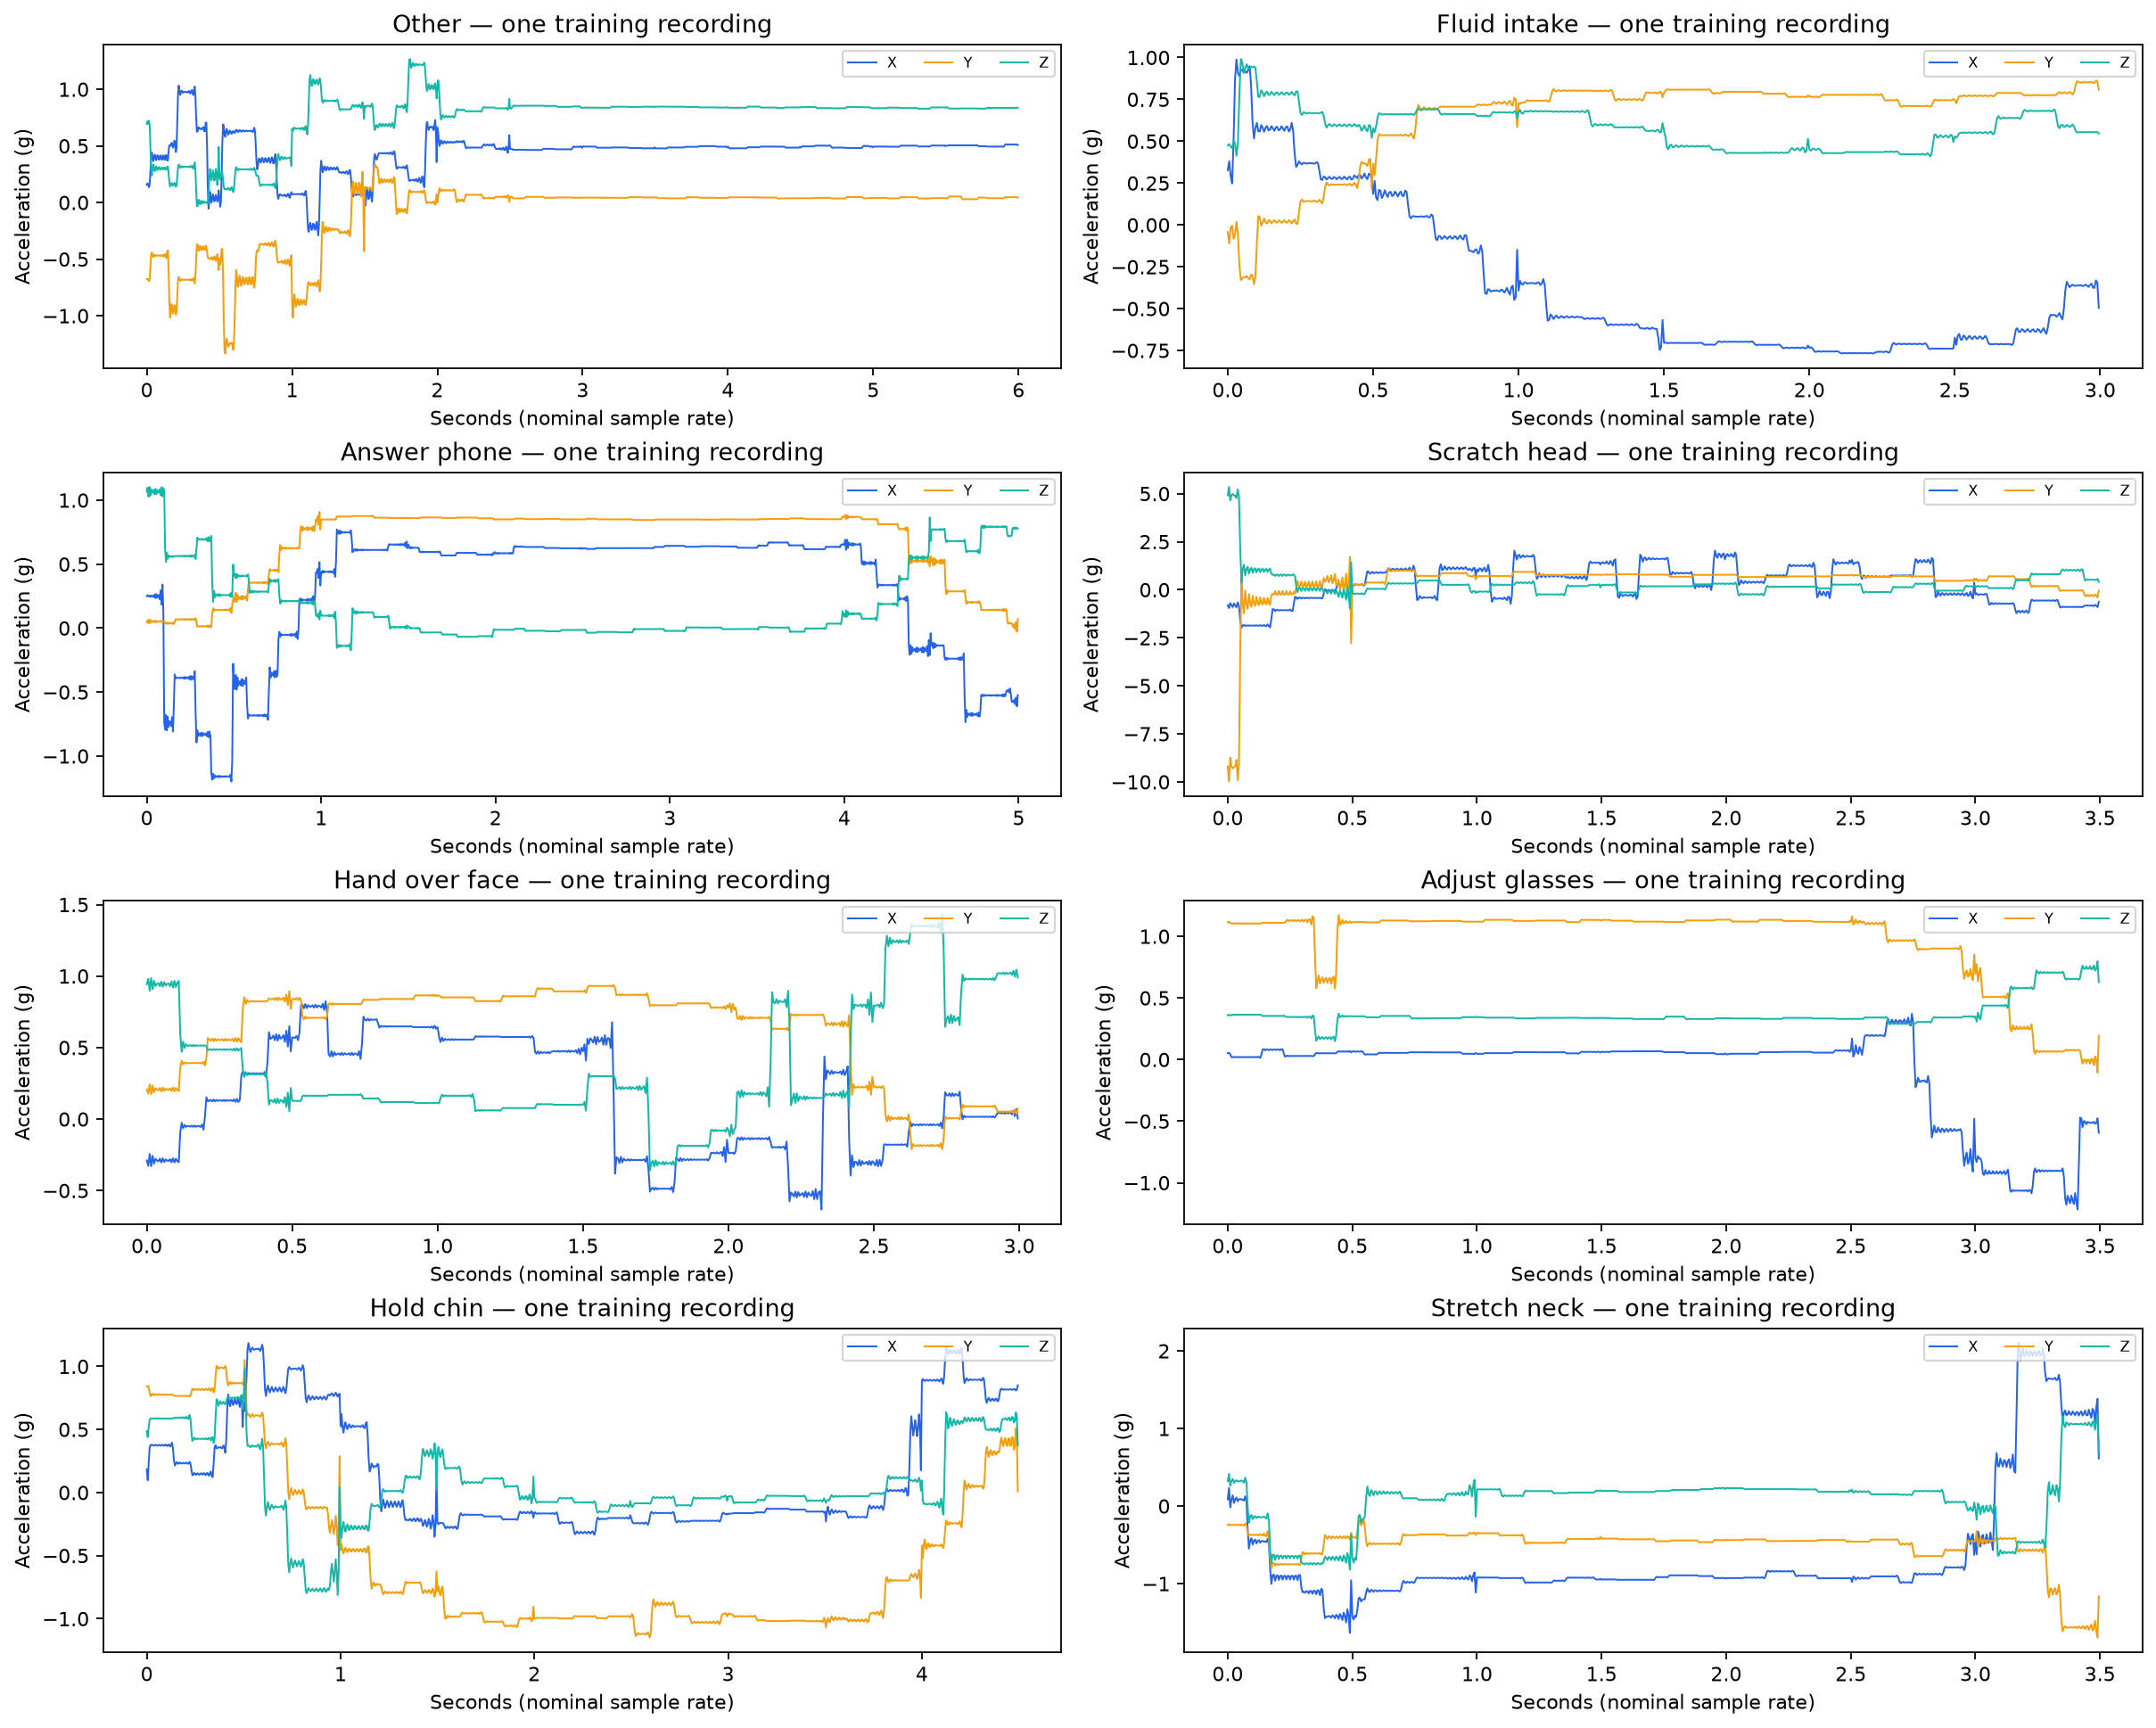

In [6]:
path = signal_examples(previews, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 3. Signal–Label Alignment — đối chiếu tín hiệu và nhãn

Đối chiếu cùng recording: tín hiệu gốc → nhãn ở mức file → cửa sổ 206 mẫu đã chuẩn hóa nhận nhãn kế thừa. Khác segmentation trong bài tham khảo, InGesture ở đây không cung cấp onset/offset cho từng điểm; dải màu là nhãn recording, không phải ranh giới cử chỉ được đo.

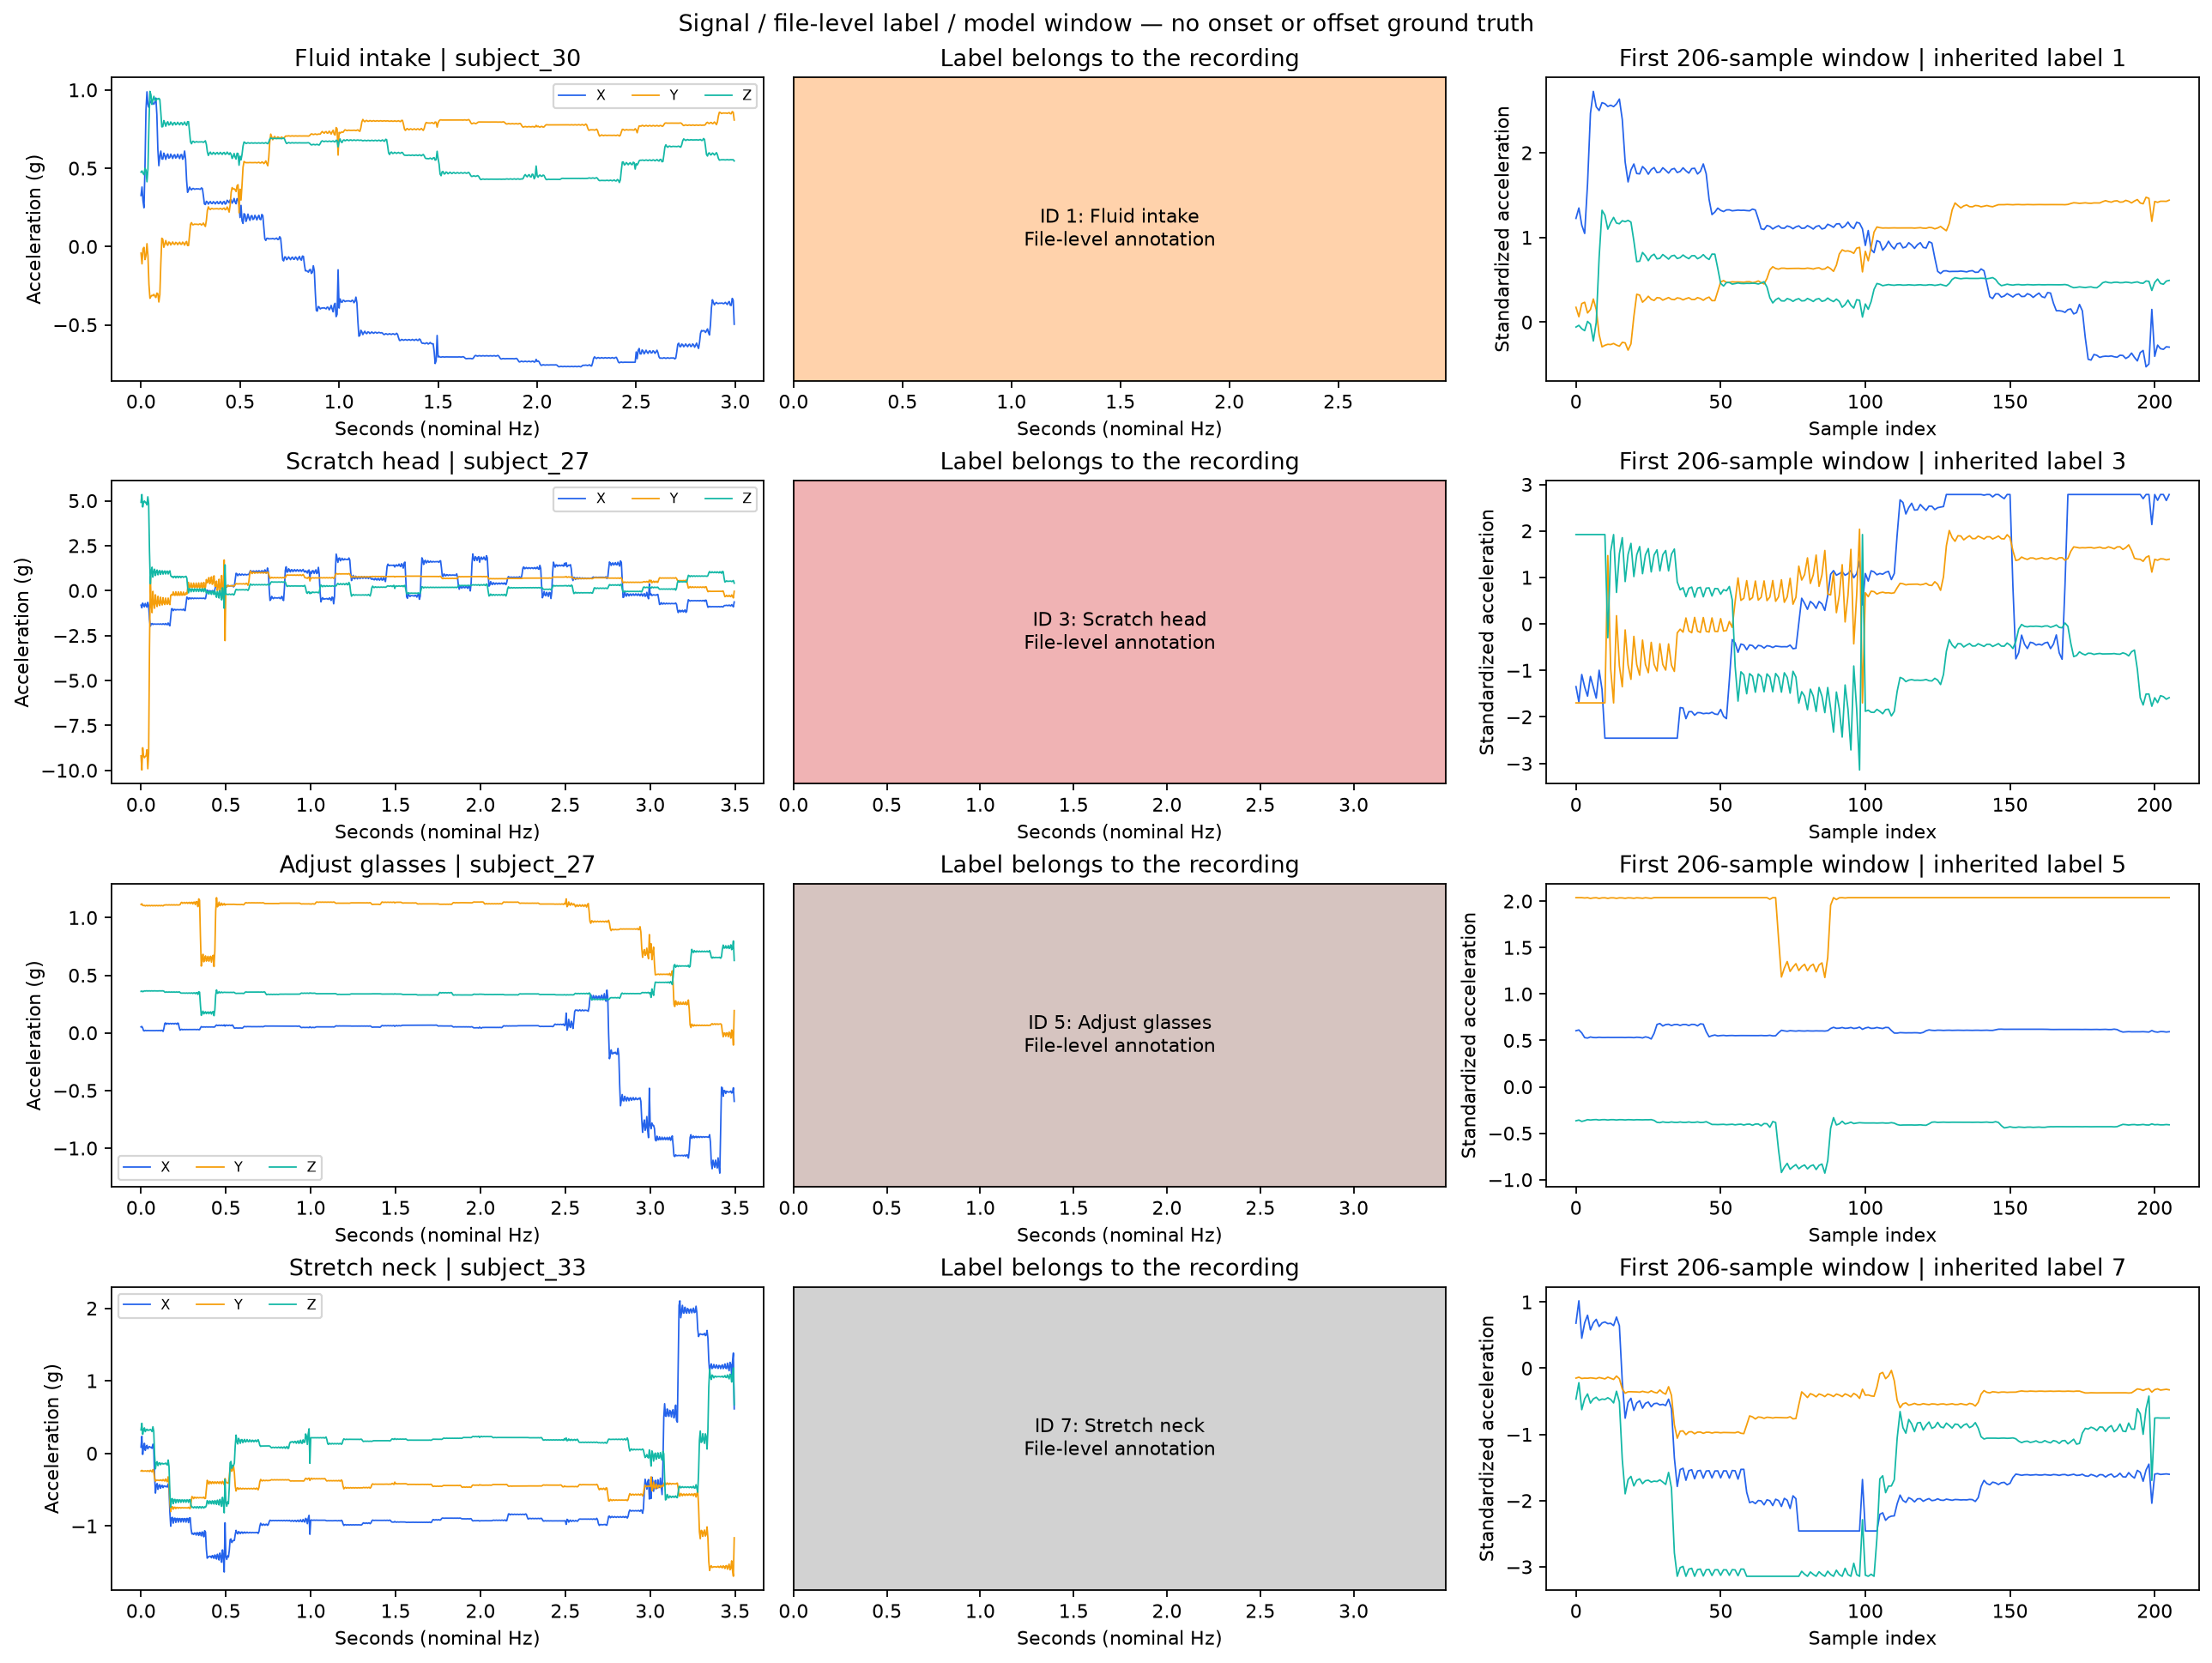

In [7]:
path = label_alignment(pool, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 4. Temporal / Frequency Visualization — phổ theo cử chỉ

Dùng đúng các recording ở mục 2. Trừ mean và dùng Hann window để nhìn dao động, giới hạn 0–30 Hz. FFT minh họa này khác frequency view huấn luyện abs(FFT)+log1p.

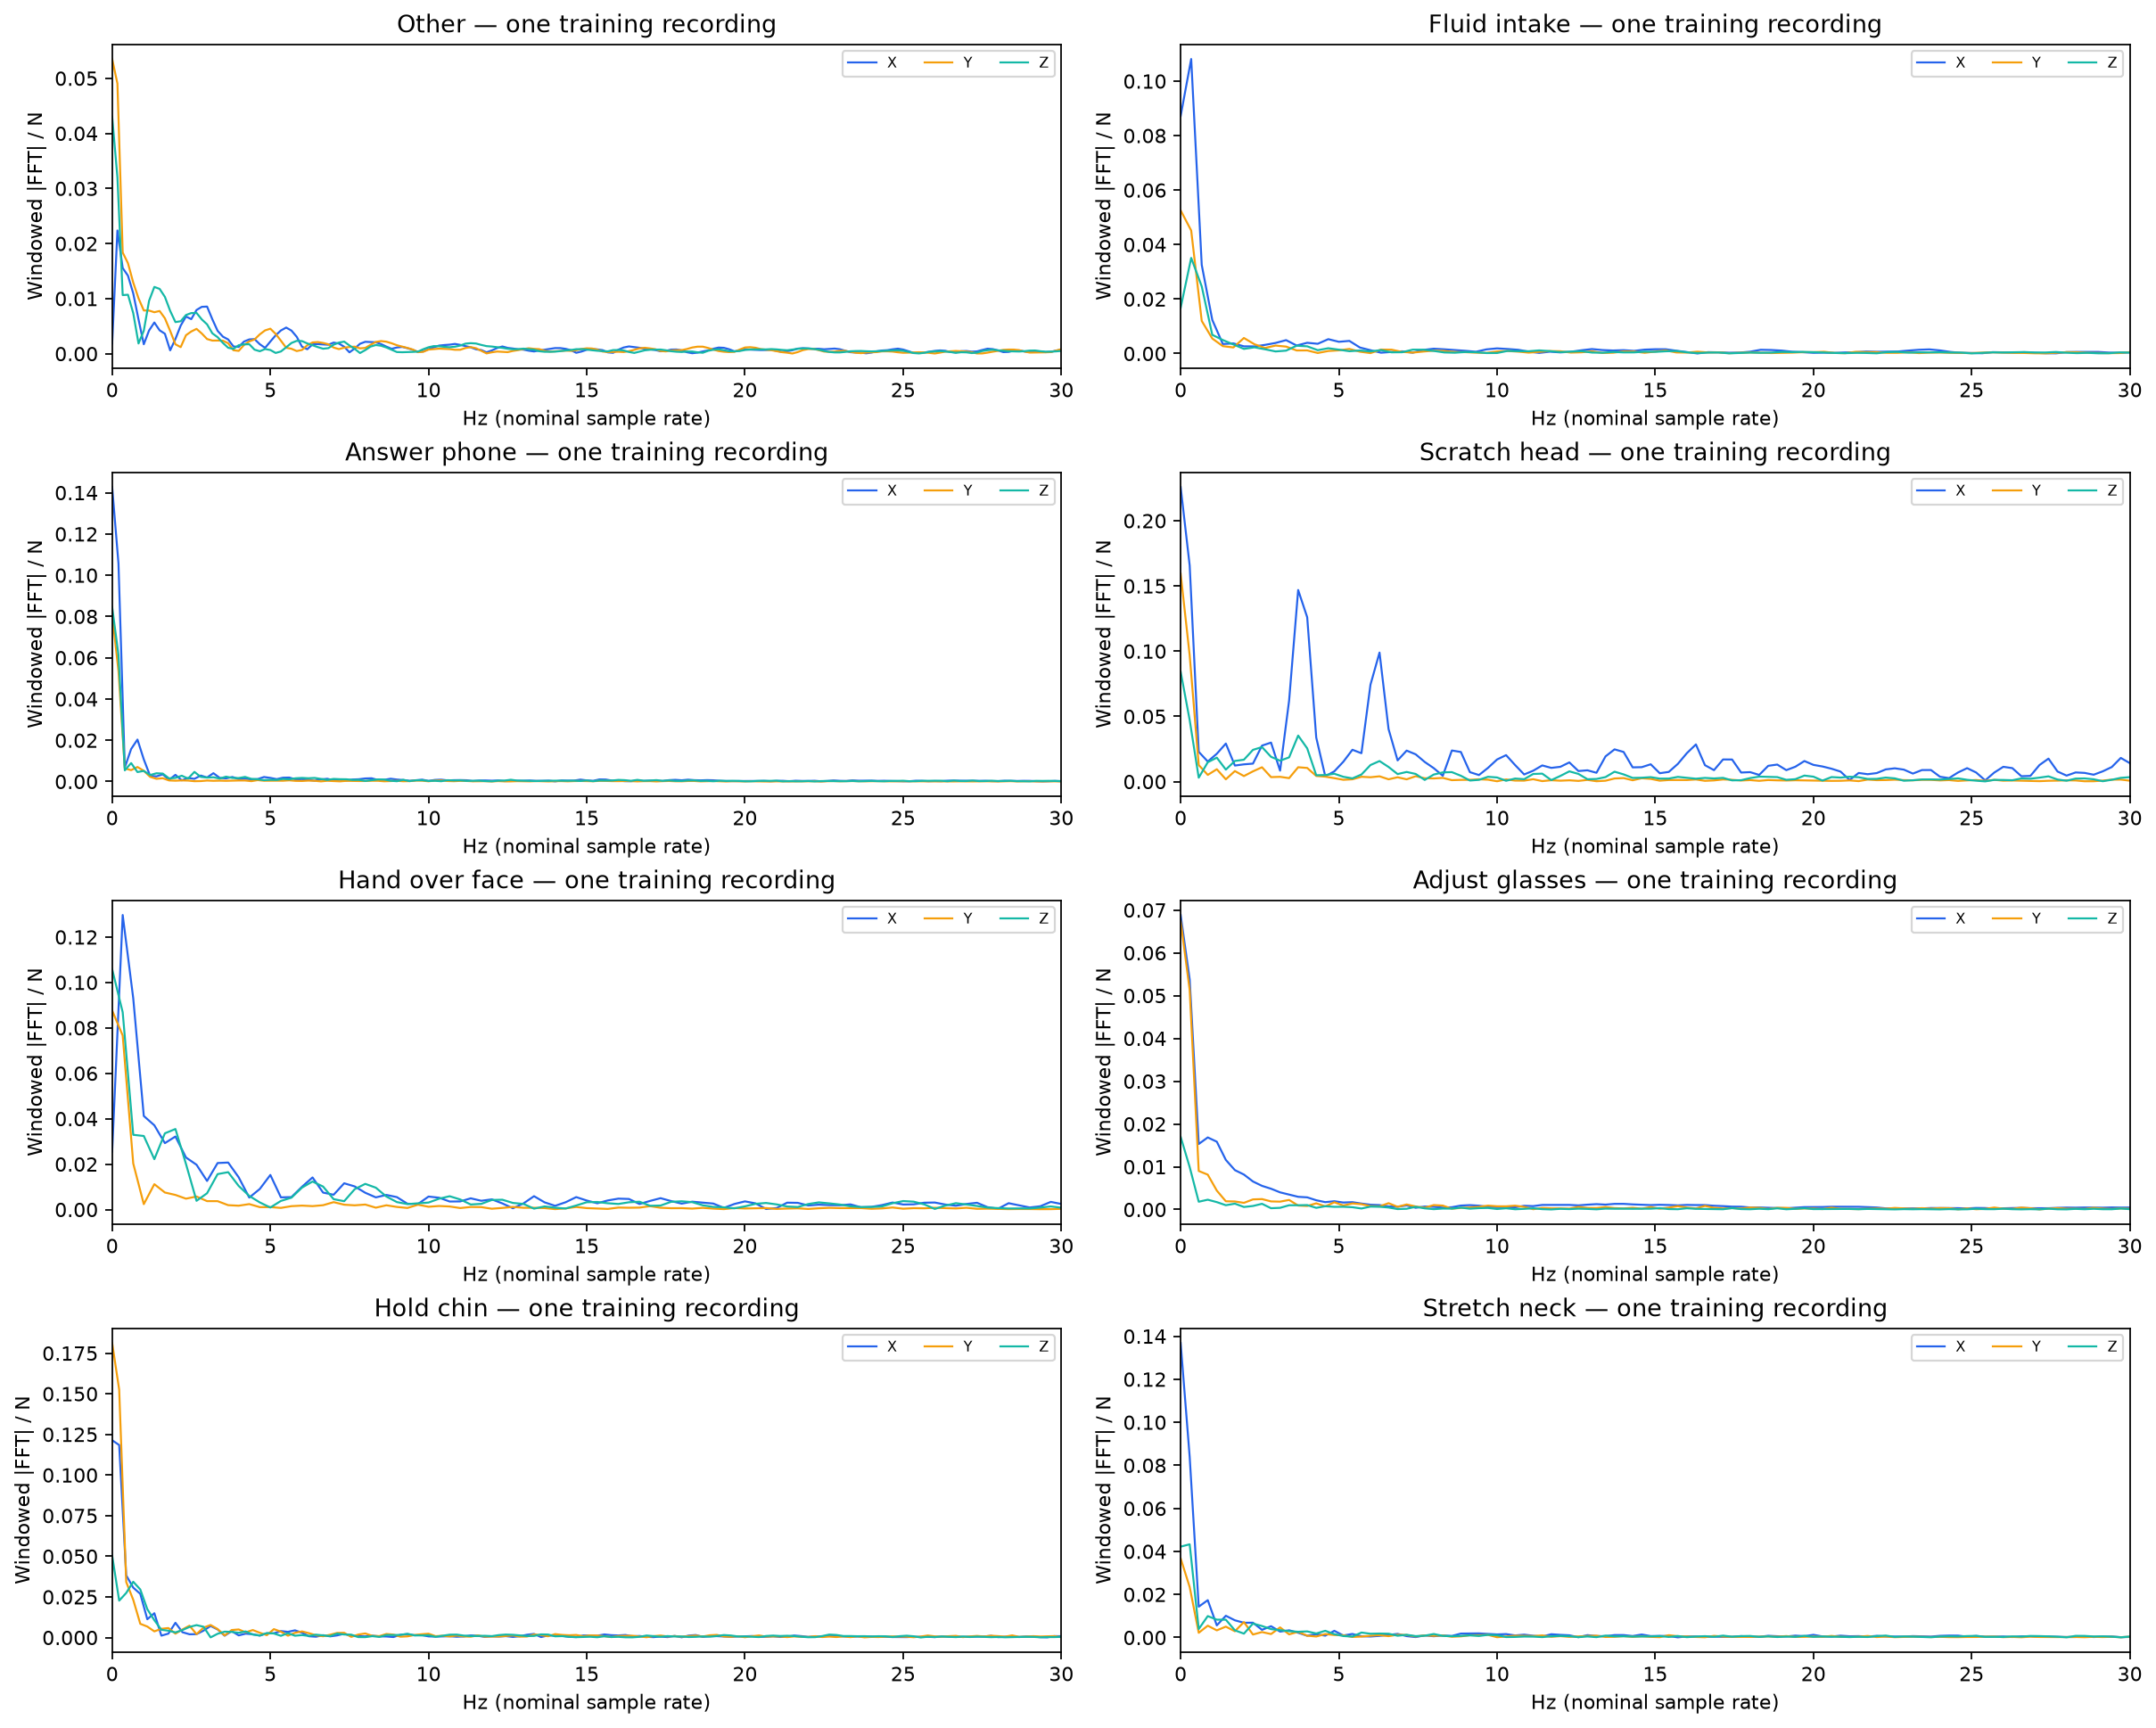

In [8]:
path = signal_examples(previews, METADATA, OUTPUT, frequency=True)
display(Image(filename=str(path)))

## 5. Multi-Subject Inspection — cùng cử chỉ ở nhiều người

Bốn cử chỉ, mỗi cử chỉ lấy ba người khác nhau từ pool. Vẽ độ lớn gia tốc sqrt(x²+y²+z²), giữ cùng trục y trong mỗi hàng để thấy biến thiên giữa người. Tên subject hiện ngay trên hình.

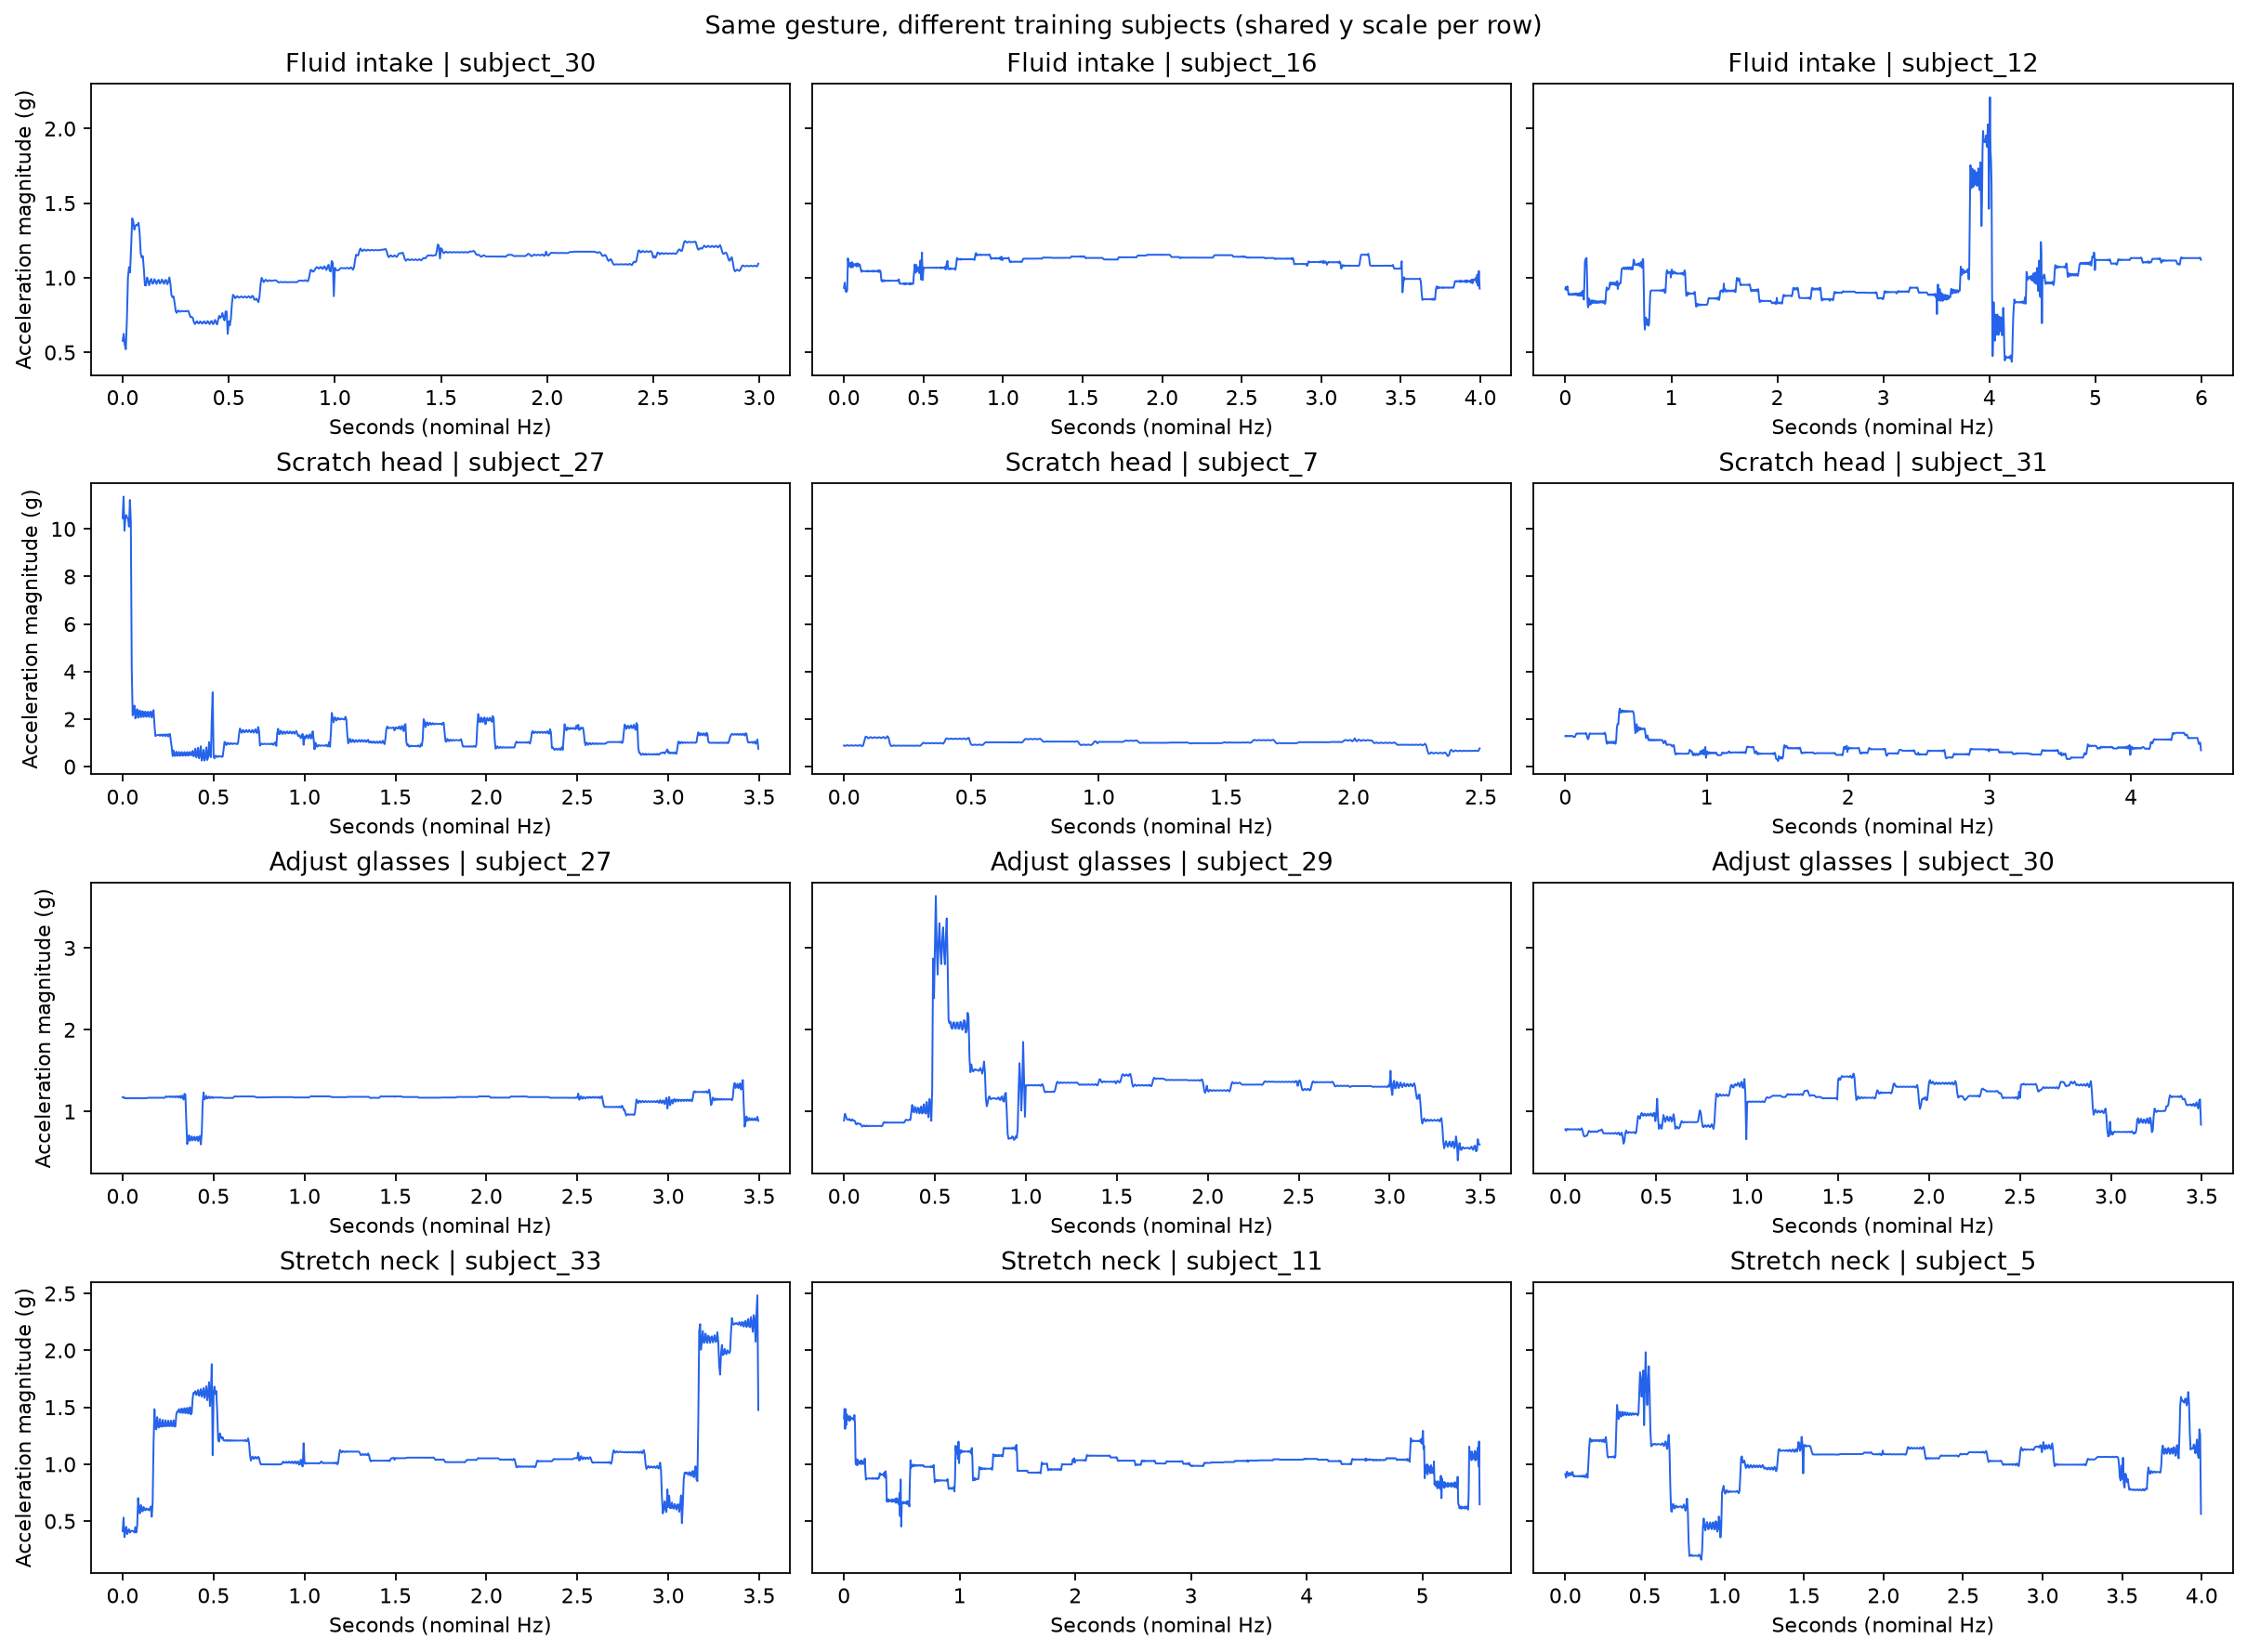

In [9]:
path = multisubject_examples(pool, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 6. Subject Coverage — độ phủ người và nhãn

Tương ứng phần coverage trong bài tham khảo, dùng toàn bộ inventory thay vì chỉ sample pool. Mỗi ô là số segmented recording của một người/cử chỉ.

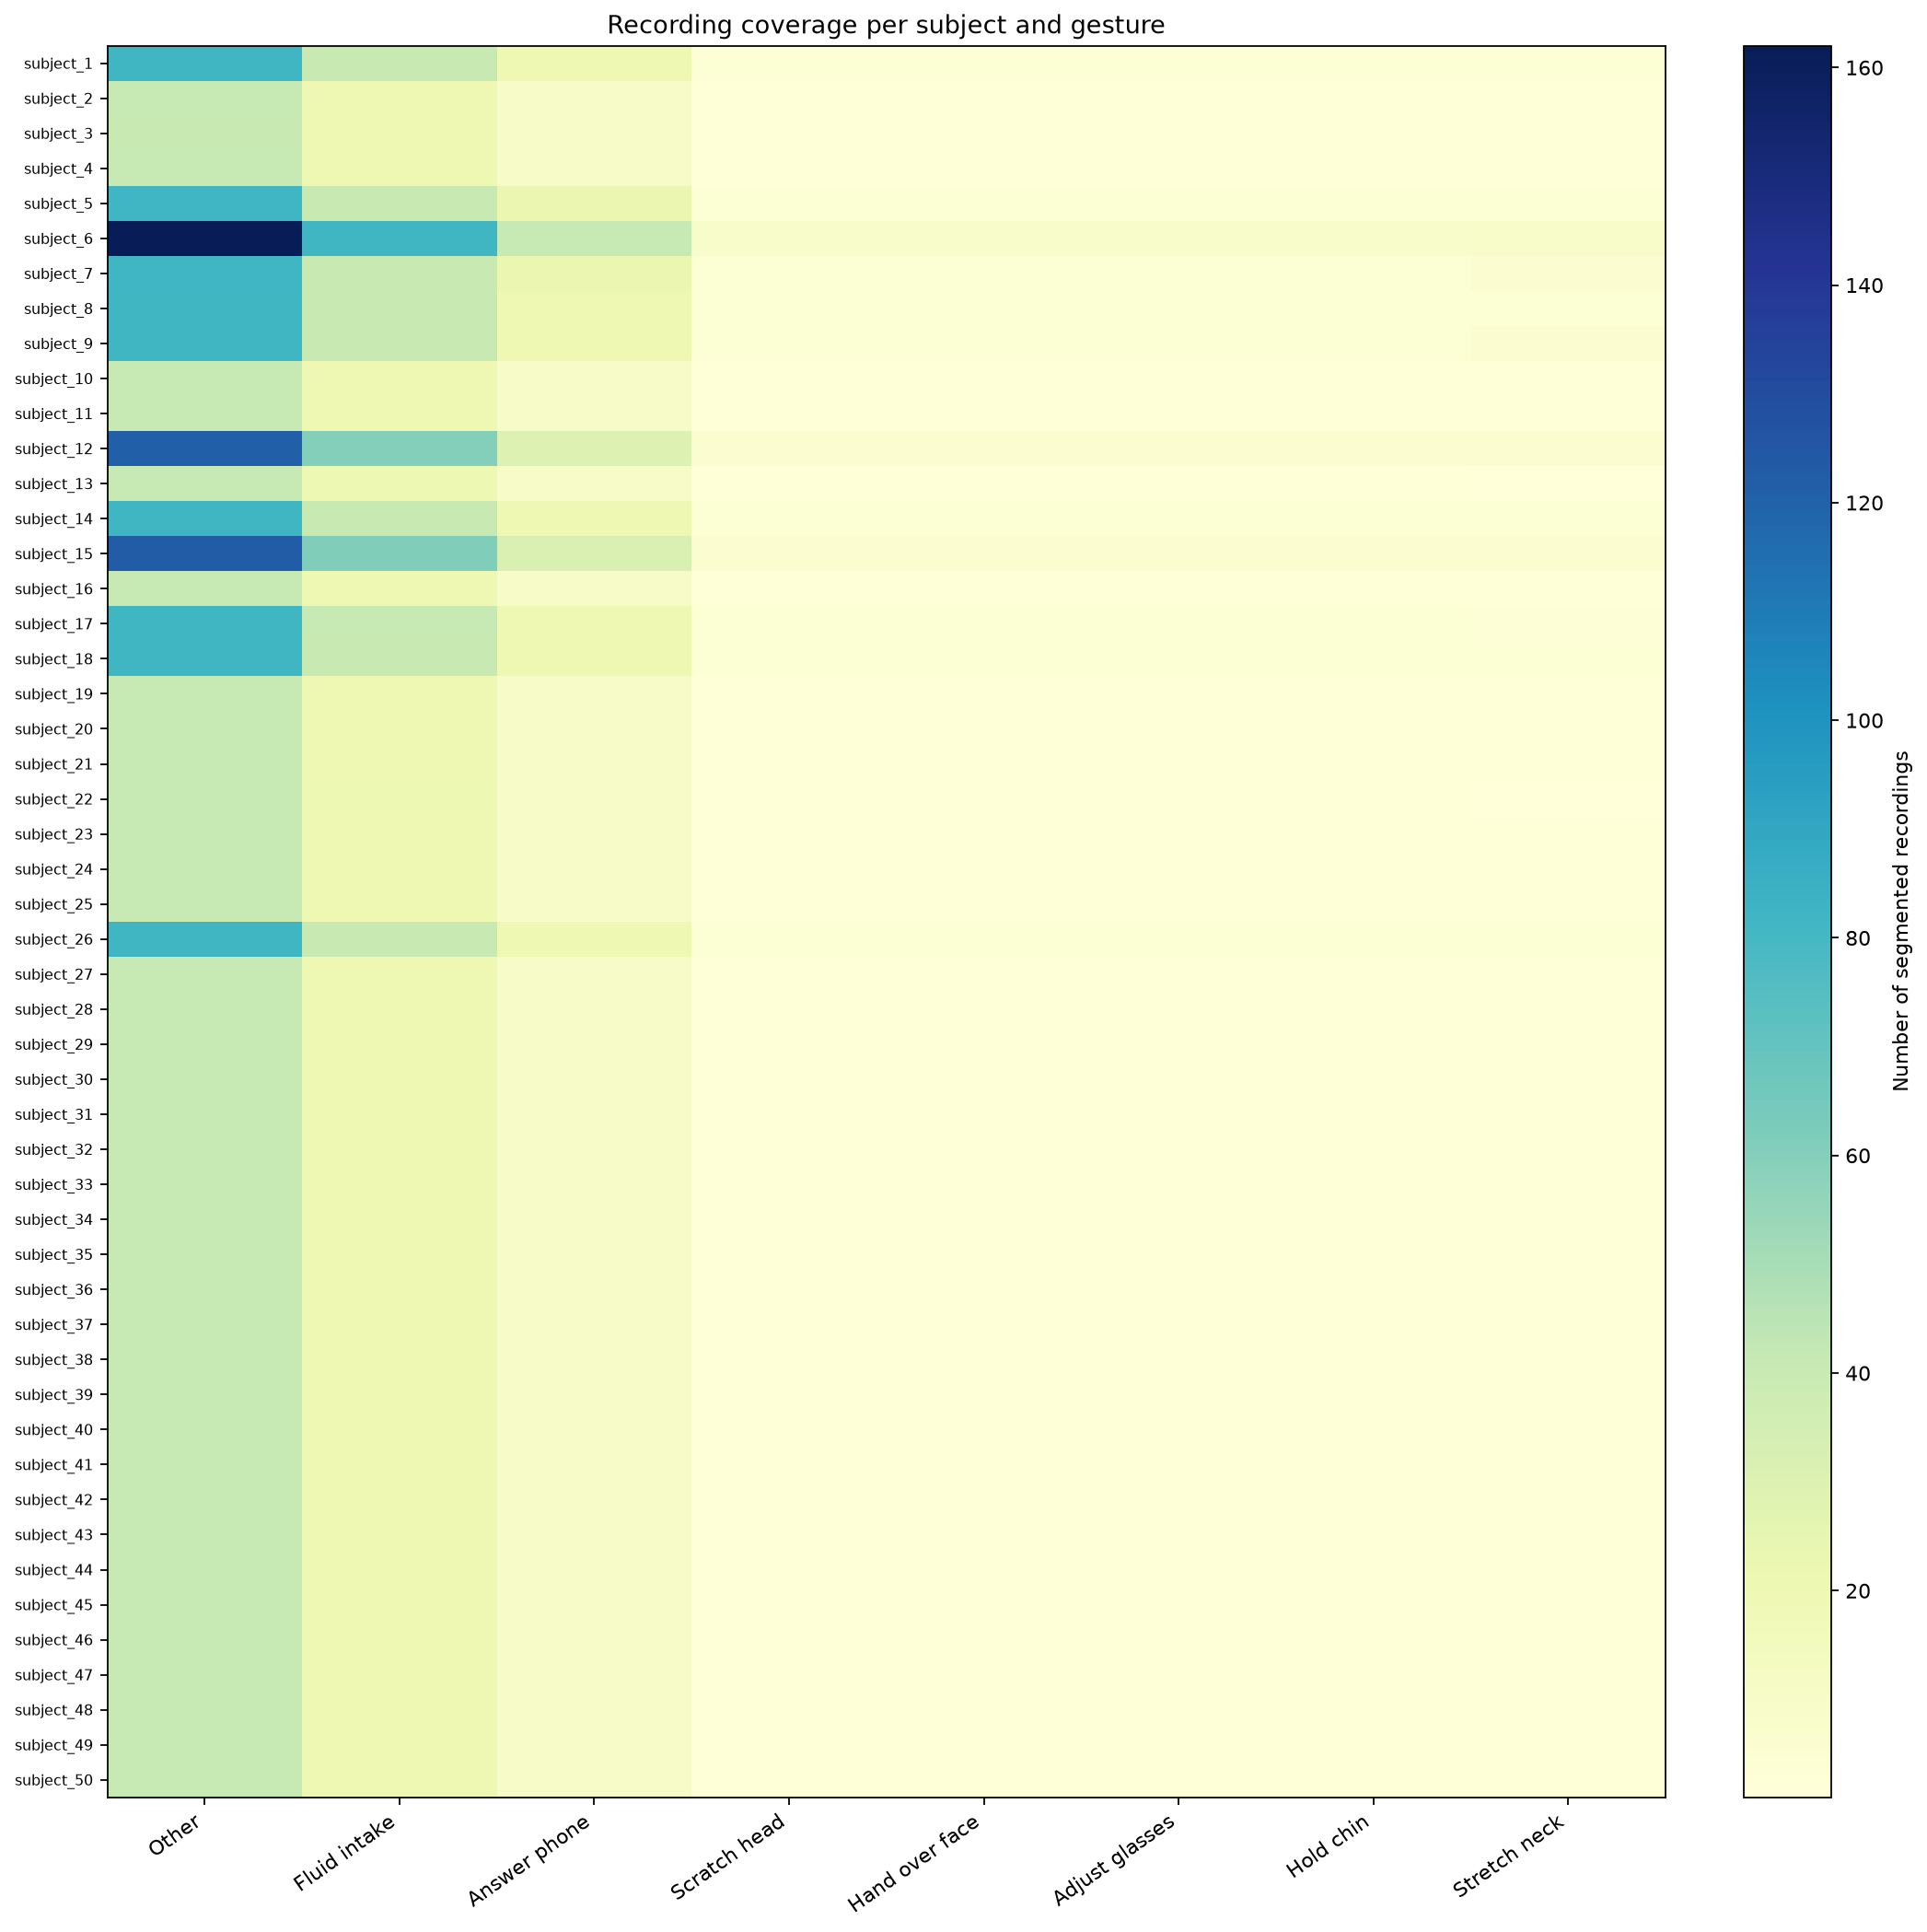

In [10]:
path = subject_coverage(frame, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 7. Class Distribution — phân bố lớp toàn dataset

So sánh số recording và số cửa sổ: một recording dài có thể sinh nhiều cửa sổ. Trục đếm dùng log; không được hiểu số cửa sổ là số người độc lập.

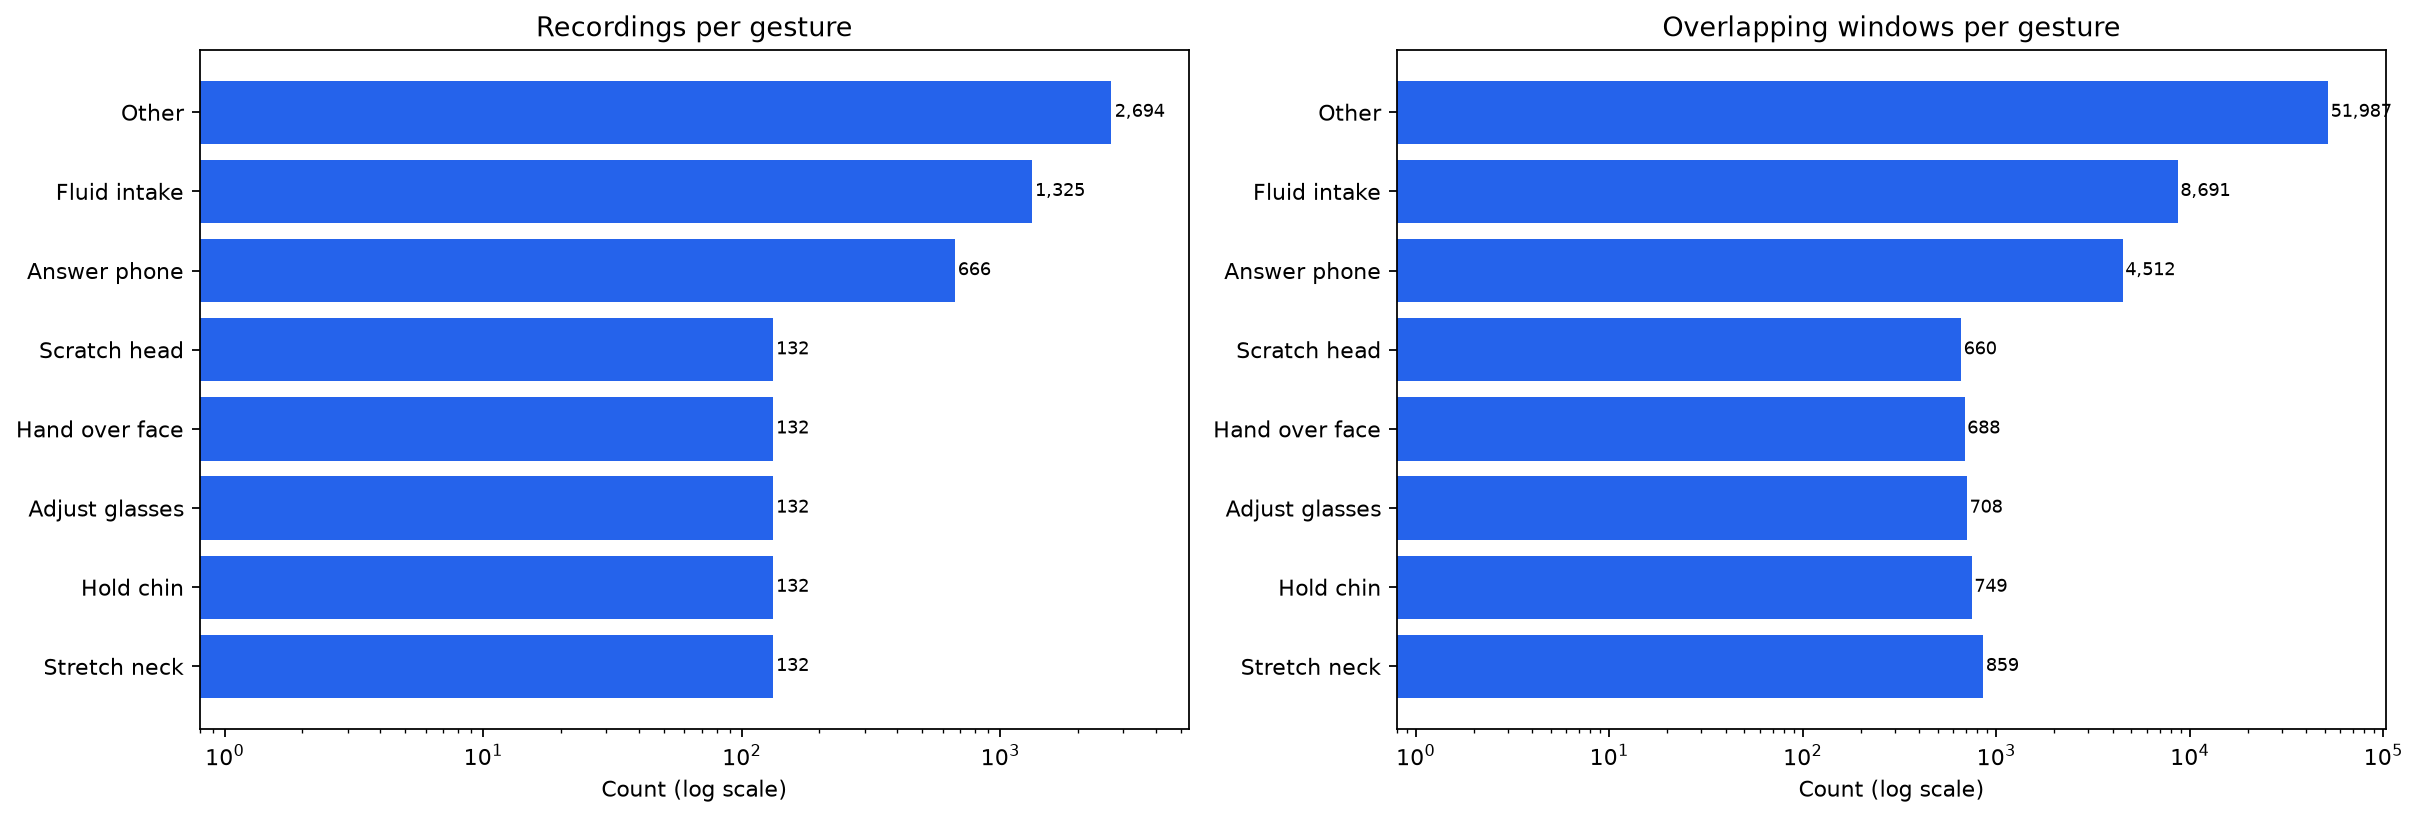

In [11]:
path = class_distribution(frame, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 8. Split Distribution — phân bố train/validation/test

Giữ phân bố thực của validation/test. Số liệu trên ô là số cửa sổ; màu dùng log(1 + count).

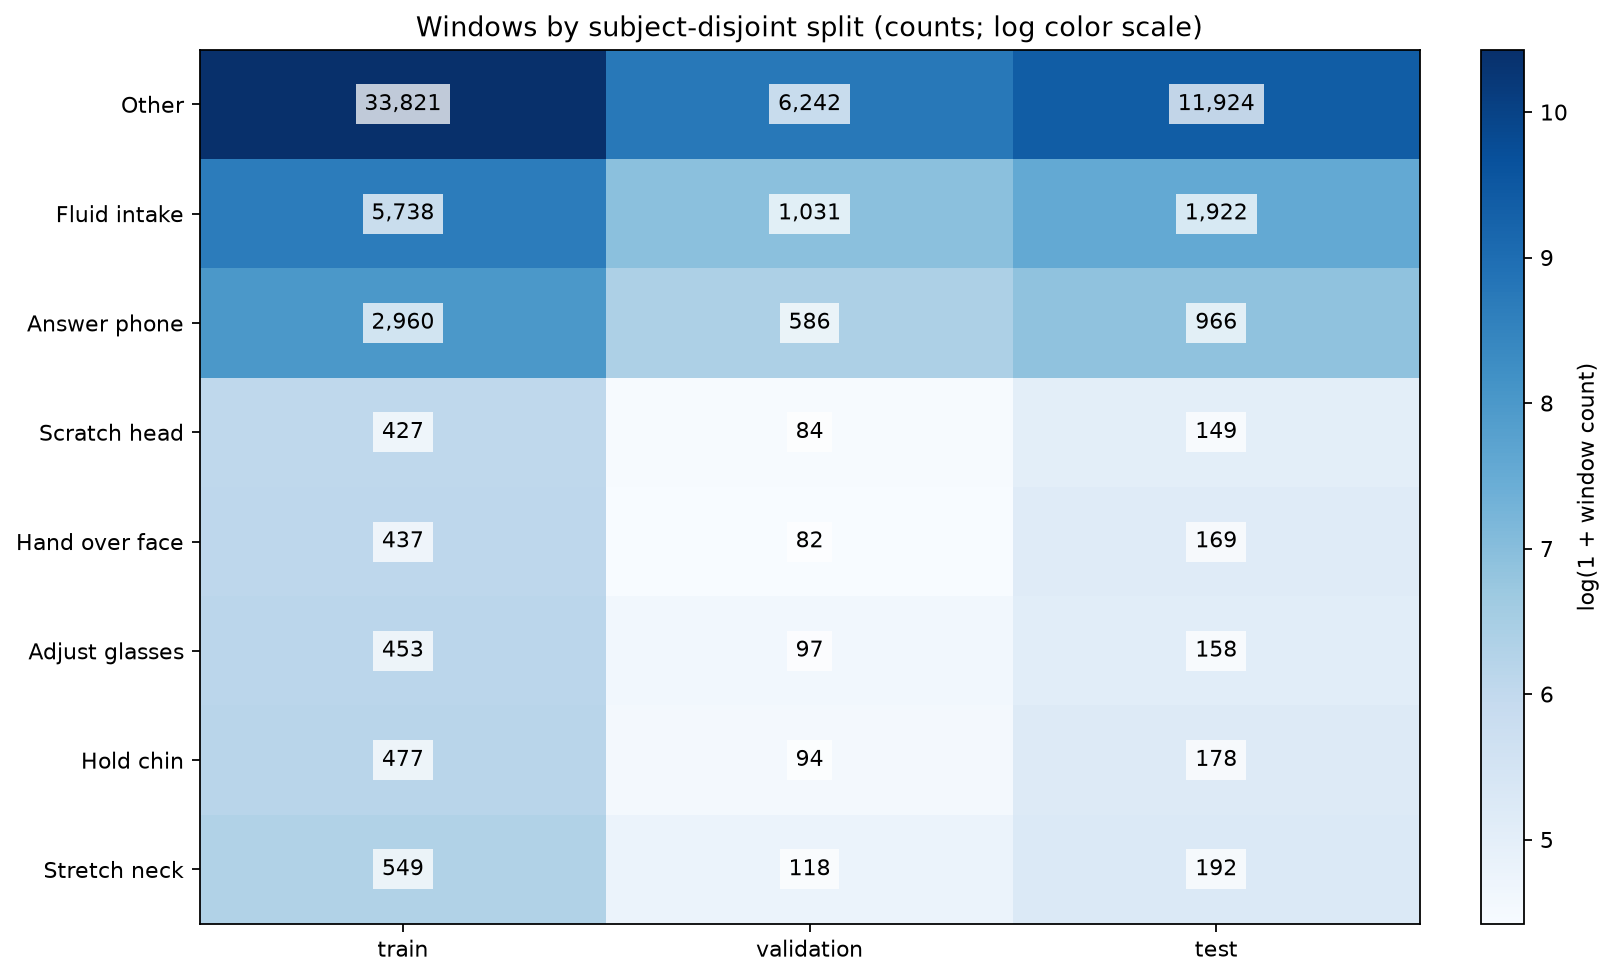

In [12]:
path = split_distribution(frame, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 9. Temporal Coverage and Quality — thời lượng và chất lượng

Thời lượng được ước lượng từ số mẫu / 200 Hz, không suy ra từ timestamp. NaN/Inf được nội suy trong từng recording. Không loại bỏ outlier khỏi biểu đồ thống kê chất lượng; boxplot thời lượng ẩn các điểm outlier để dễ đọc.

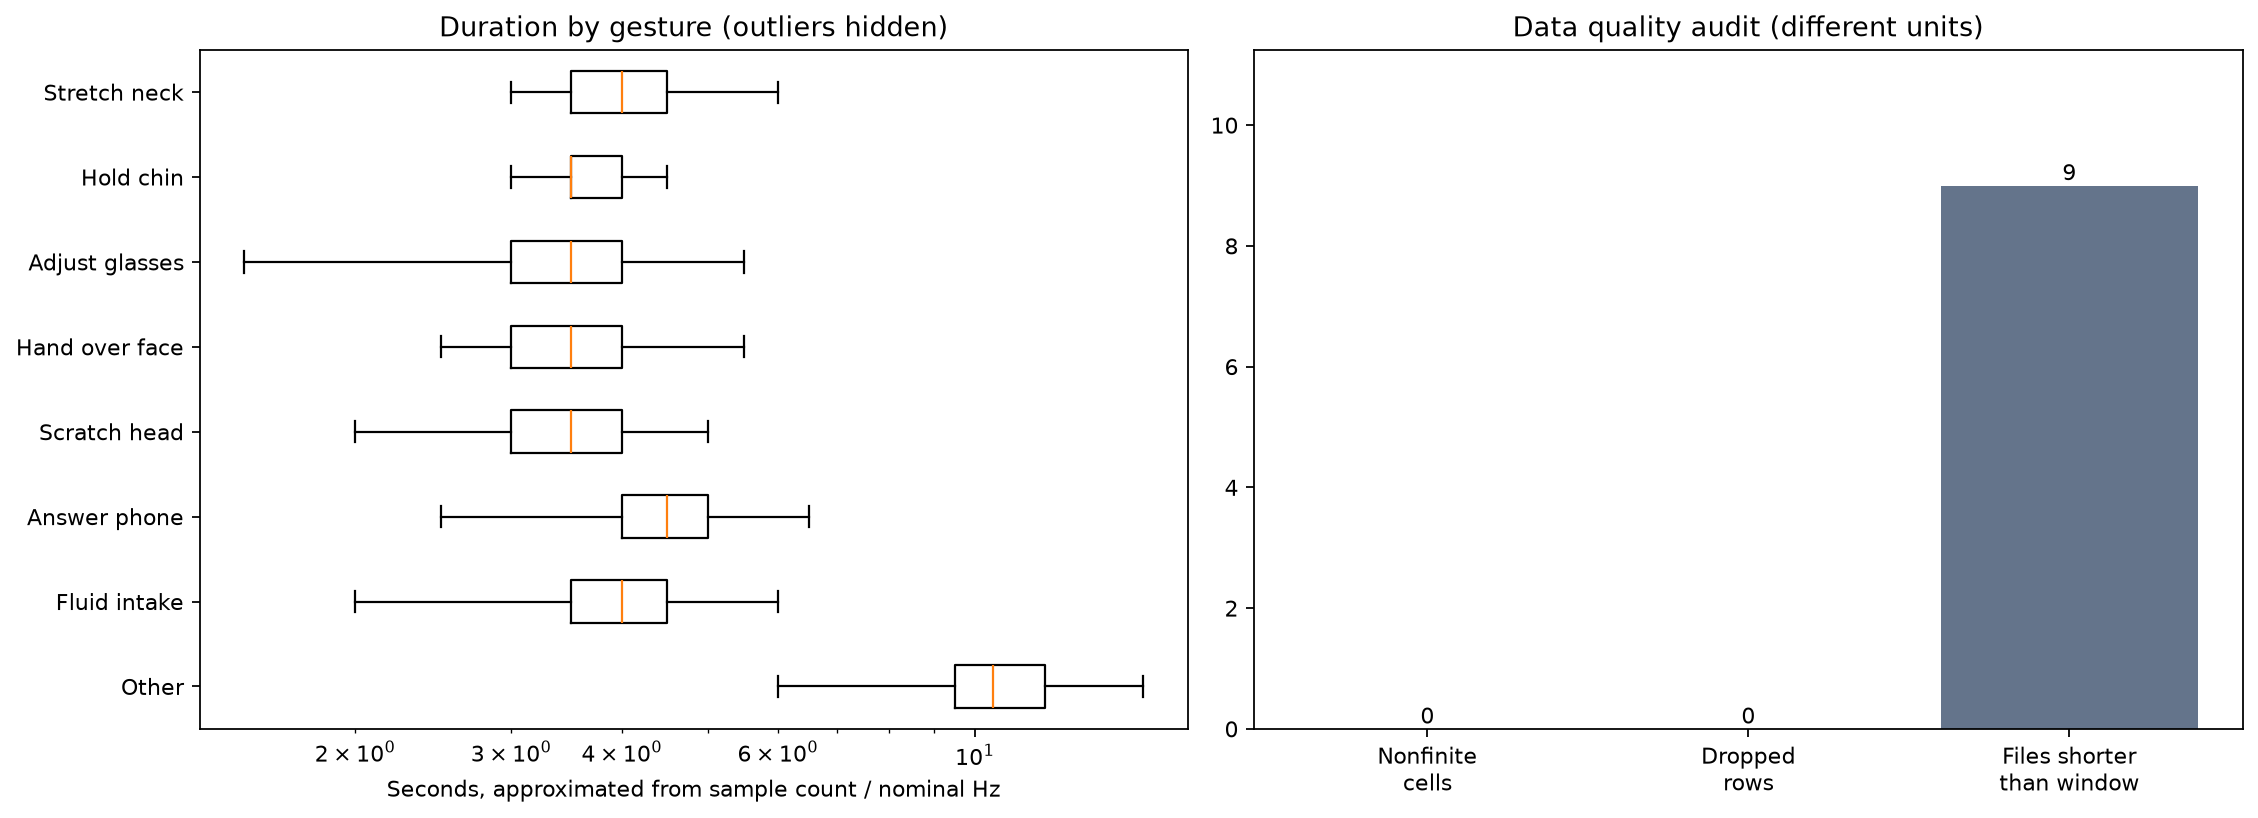

In [13]:
path = quality(frame, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 10. Gesture Profiles — đường trung bình và độ biến thiên

Tương ứng đường mean ± SD theo lớp trong bài tham khảo. Mỗi recording được nội suy về 200 điểm theo tiến độ tương đối 0–100%, chỉ để vẽ. Dải màu là ±1 độ lệch chuẩn giữa recording, không phải confidence interval. Không có căn chỉnh onset/offset và không áp dụng phép nội suy này vào đầu vào huấn luyện.

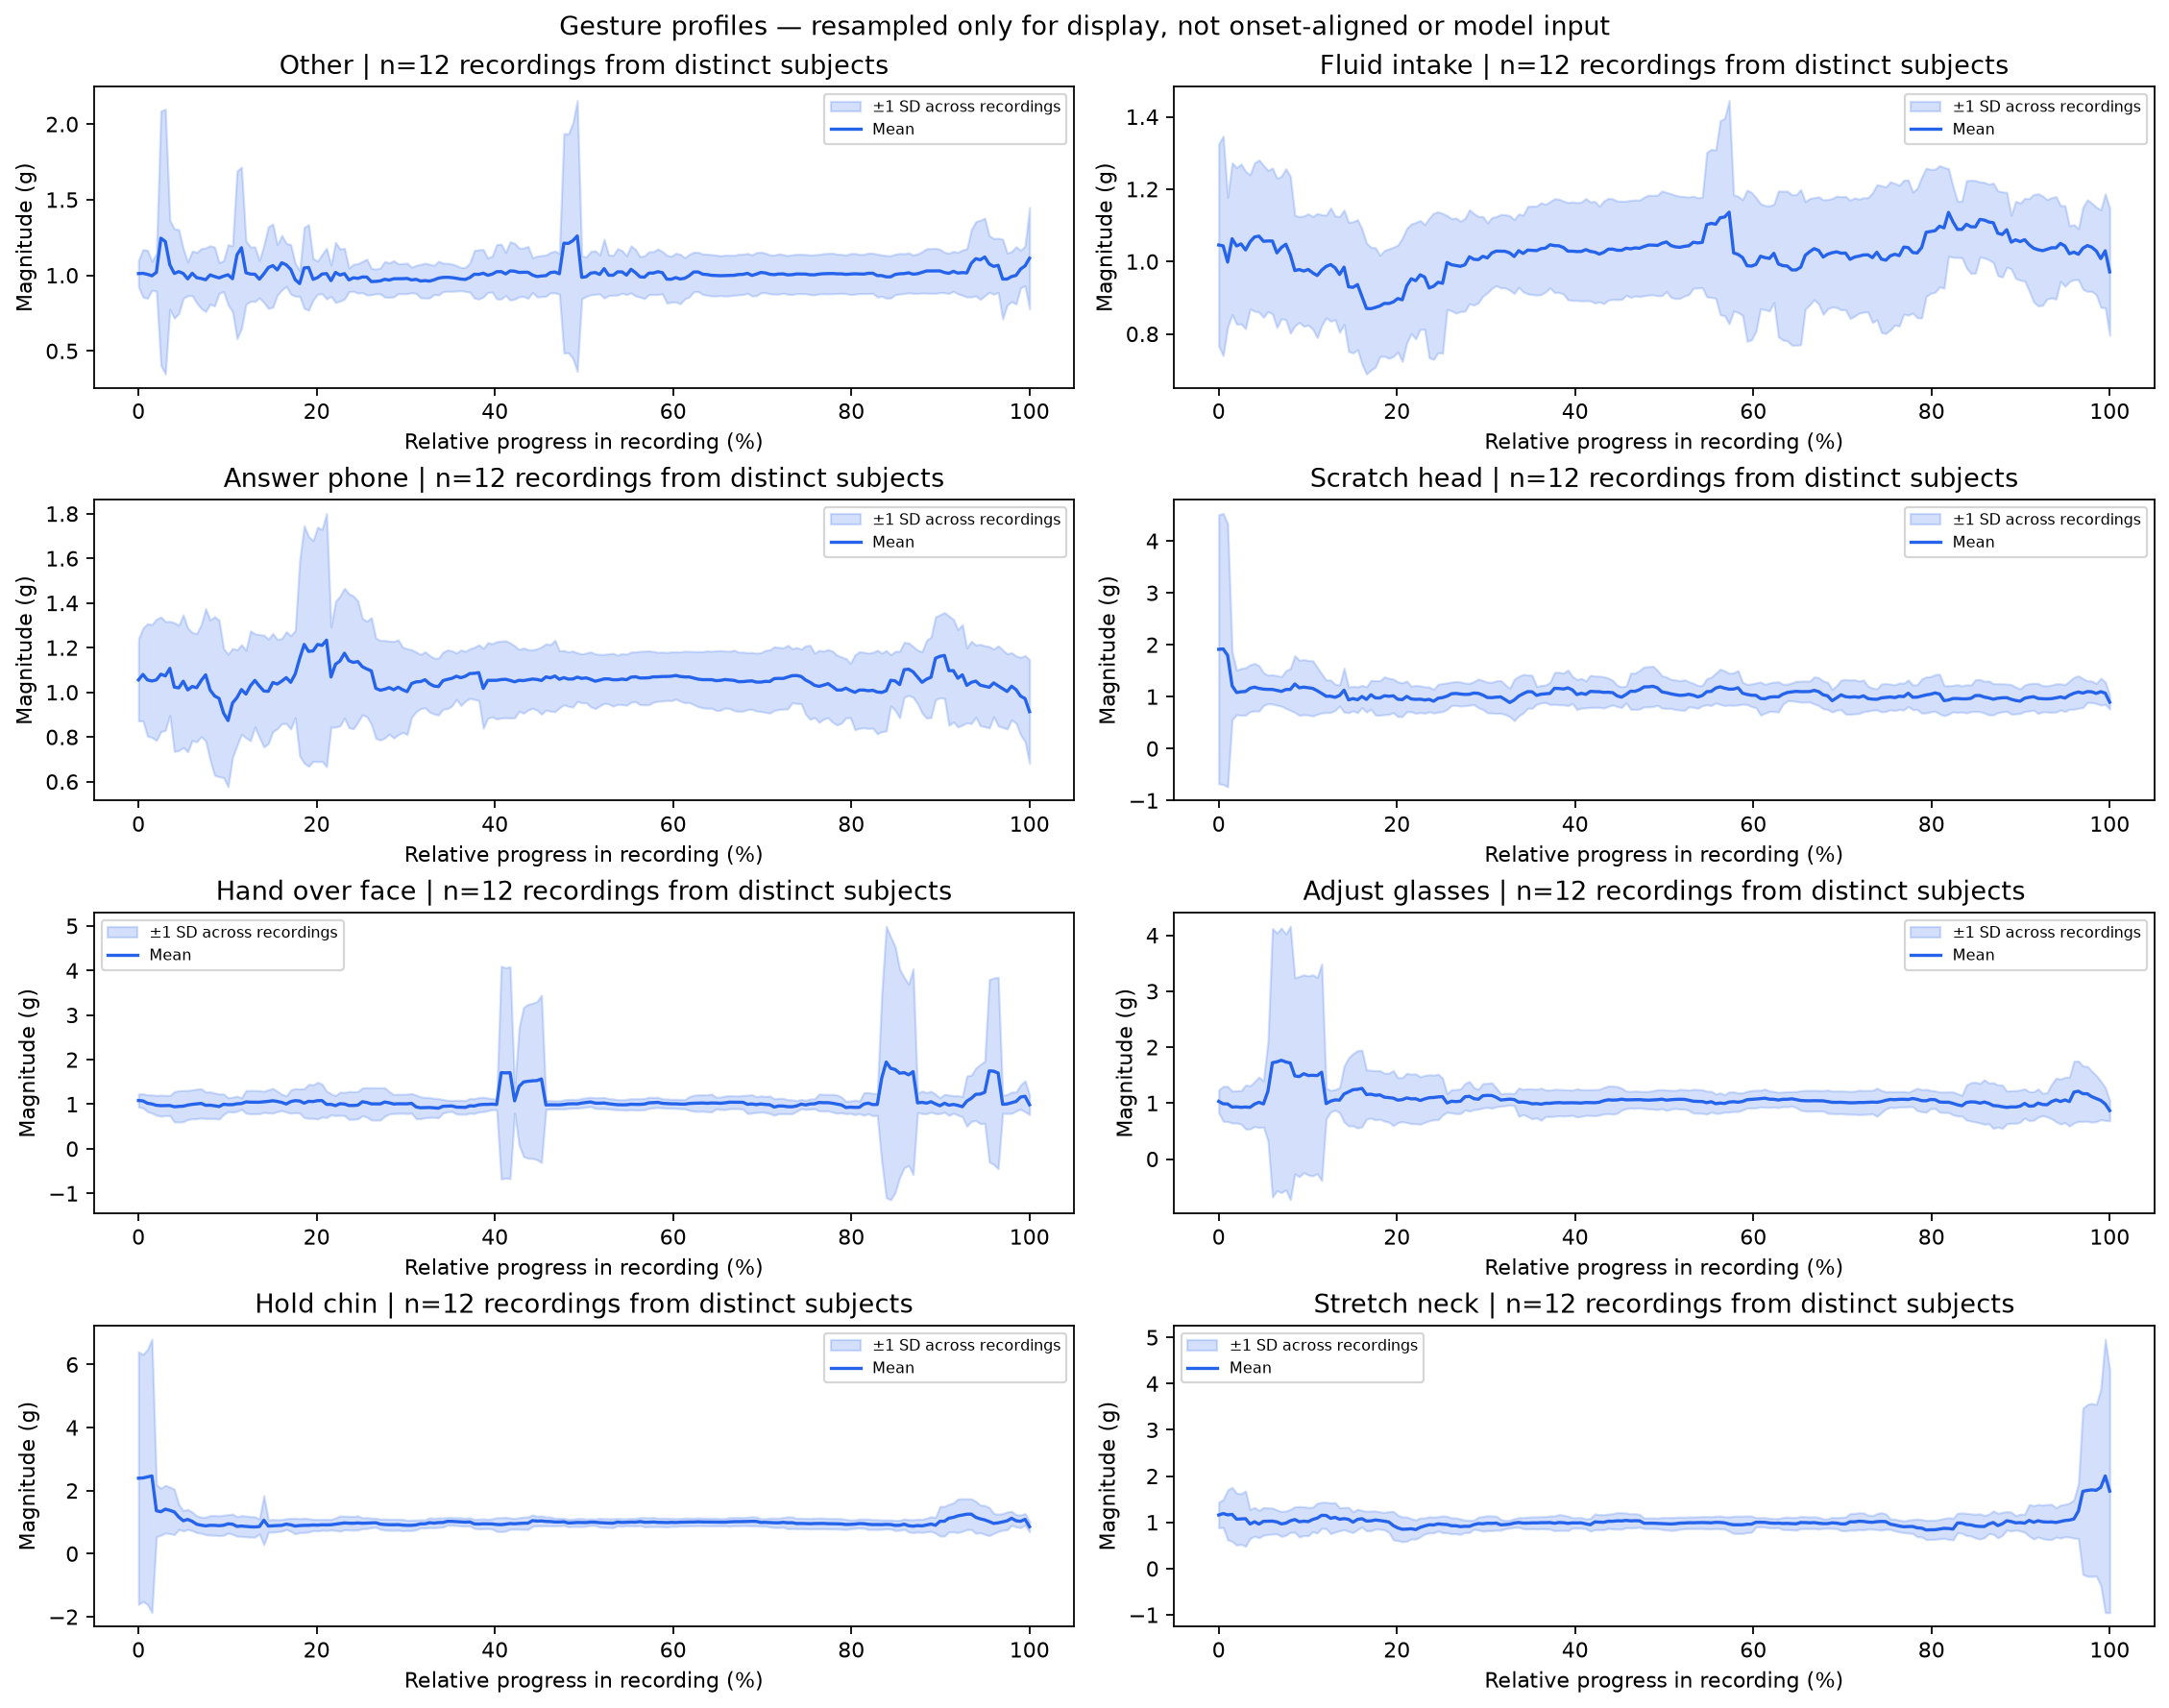

In [14]:
path = gesture_profiles(pool, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 11. Normalization and Axis Correlation

Mẫu train gồm tối đa 50 điểm/recording, chọn seed 42. Đây là lấy mẫu theo recording, không phải phân bố theo toàn bộ thời gian. Không fit lại thống kê trên validation/test.

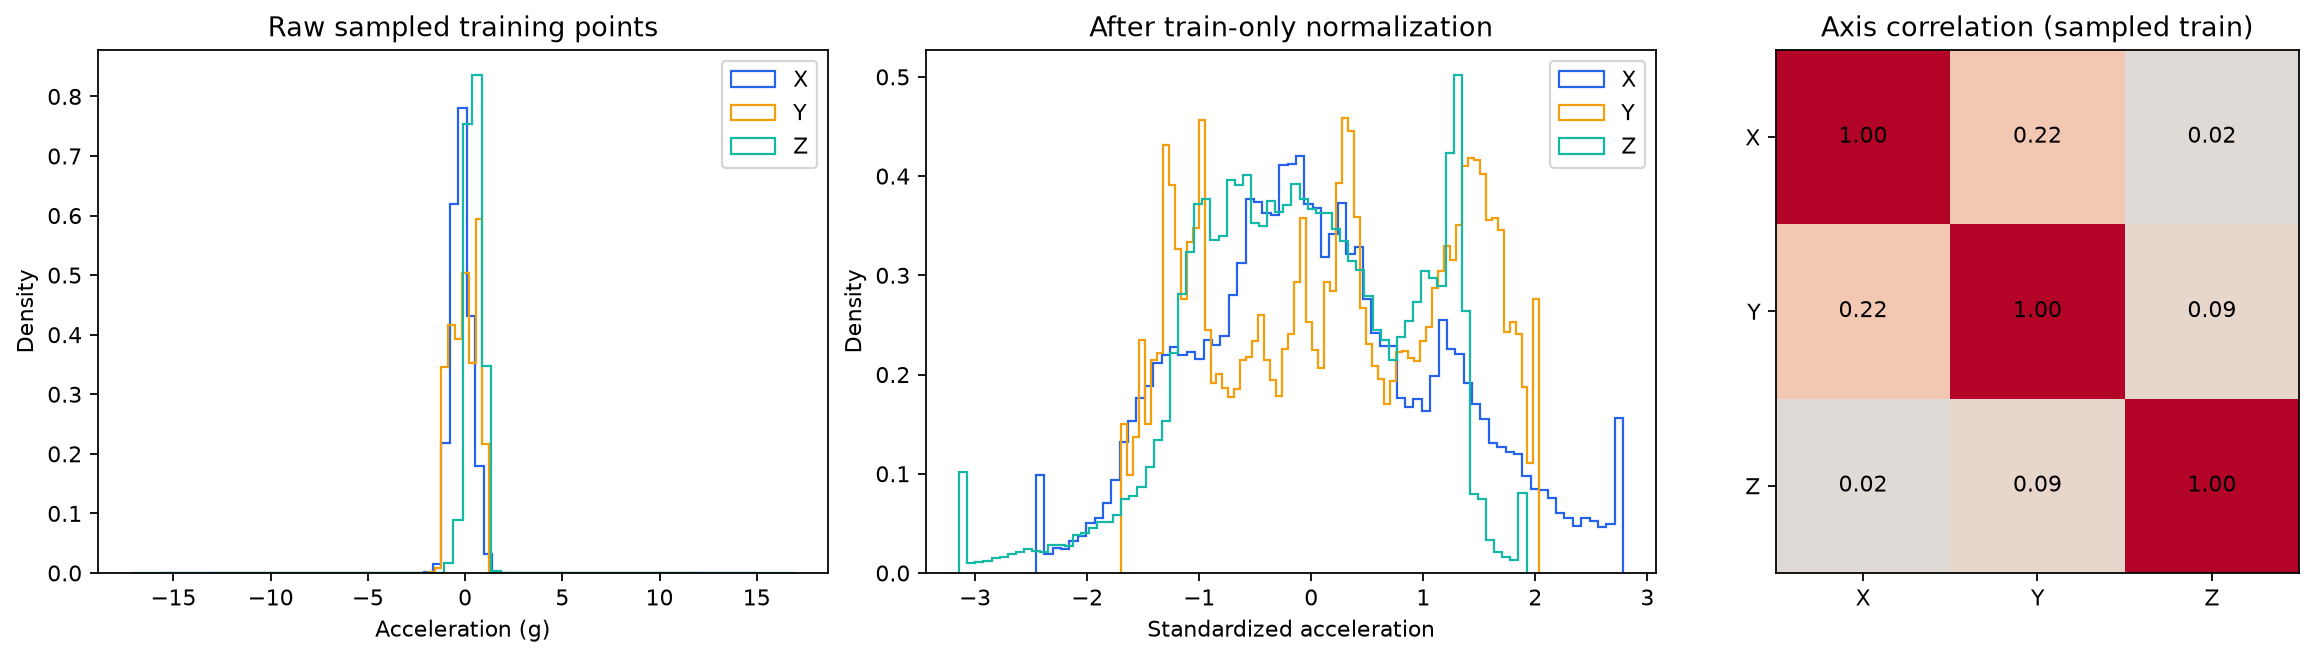

In [15]:
path = train_statistics(points, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 12. Model Input Inspection — ảnh đầu vào DINOv3

Minh họa adapter lúc khởi tạo với ánh xạ kênh identity, ảnh 64×64 trước chuẩn hóa ảnh. Không phải ảnh từ adapter đã học, GAF hay spectrogram. Các hàng lặp lại do cách trải trace thành ảnh; loss tốt hơn không bảo đảm khắc phục hạn chế của cách biểu diễn này.

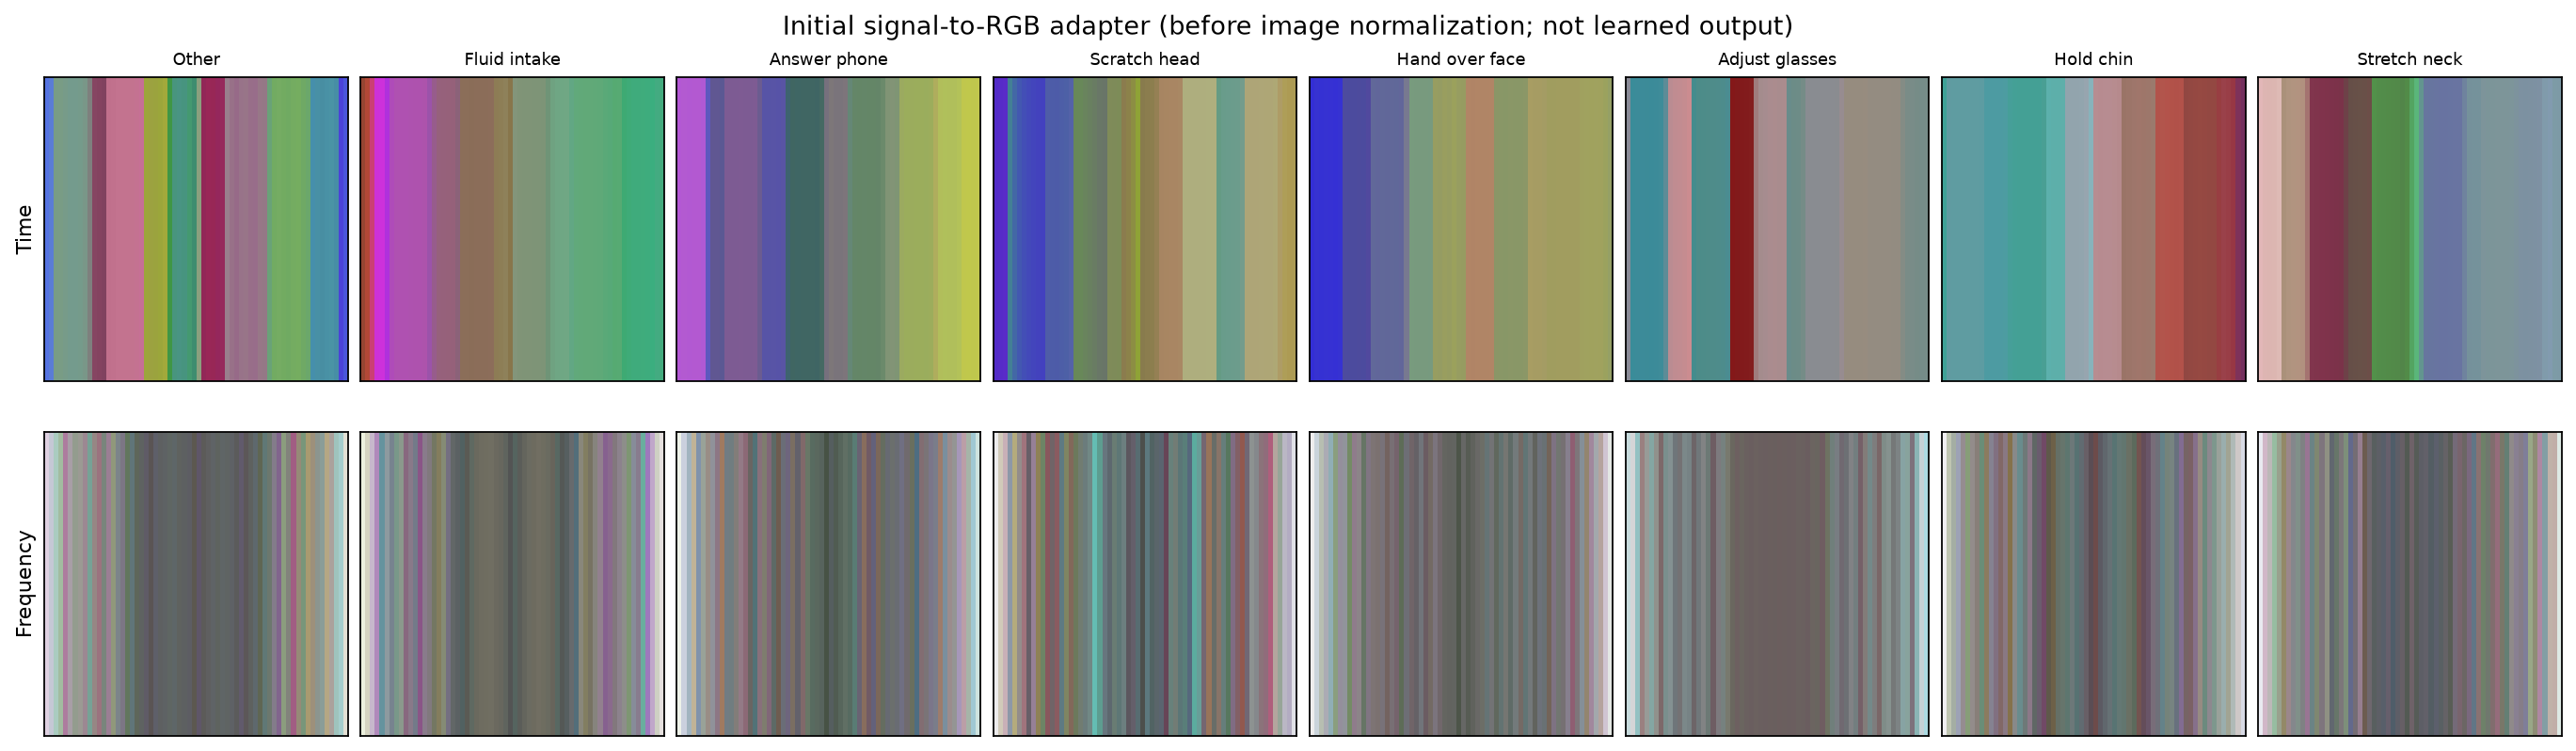

In [16]:
path = adapter_examples(previews, METADATA, OUTPUT)
display(Image(filename=str(path)))

## 13. PCA — chiếu đặc trưng thống kê lên hai chiều

Mỗi recording trong pool lấy cửa sổ đầu tiên dài 206 mẫu, chuẩn hóa bằng thống kê train. Đặc trưng gồm mean, std, RMS và khoảng percentile 5–95 cho ba trục (12 chiều). StandardScaler/PCA chỉ fit trên pool train. Mức tách cụm và phương sai giải thích không phải accuracy hoặc embedding DINOv3.

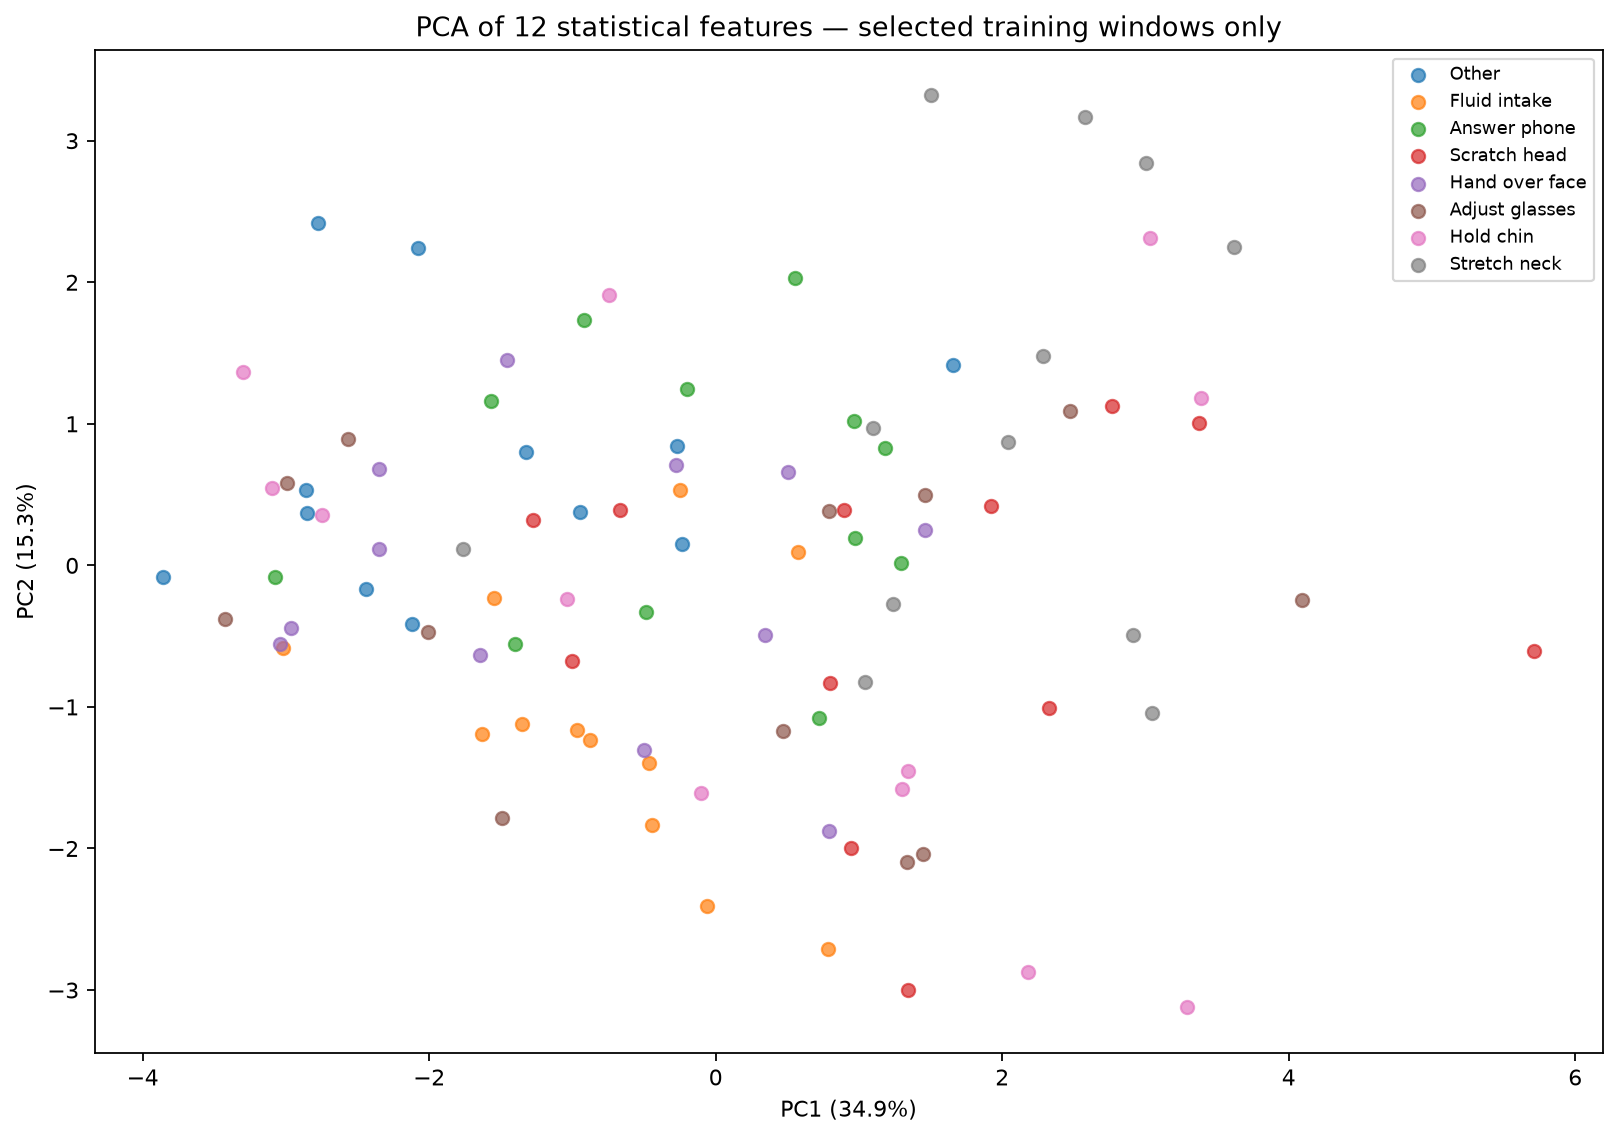

In [17]:
path = pca_features(pool,METADATA,OUTPUT)
display(Image(filename=str(path)))

## 14. Channel RMS — độ lớn theo kênh và cử chỉ

RMS được tính trên đúng các cửa sổ chuẩn hóa dùng ở mục PCA, rồi lấy trung bình theo lớp. Giá trị là đơn vị chuẩn hóa, không phải năng lượng vật lý.

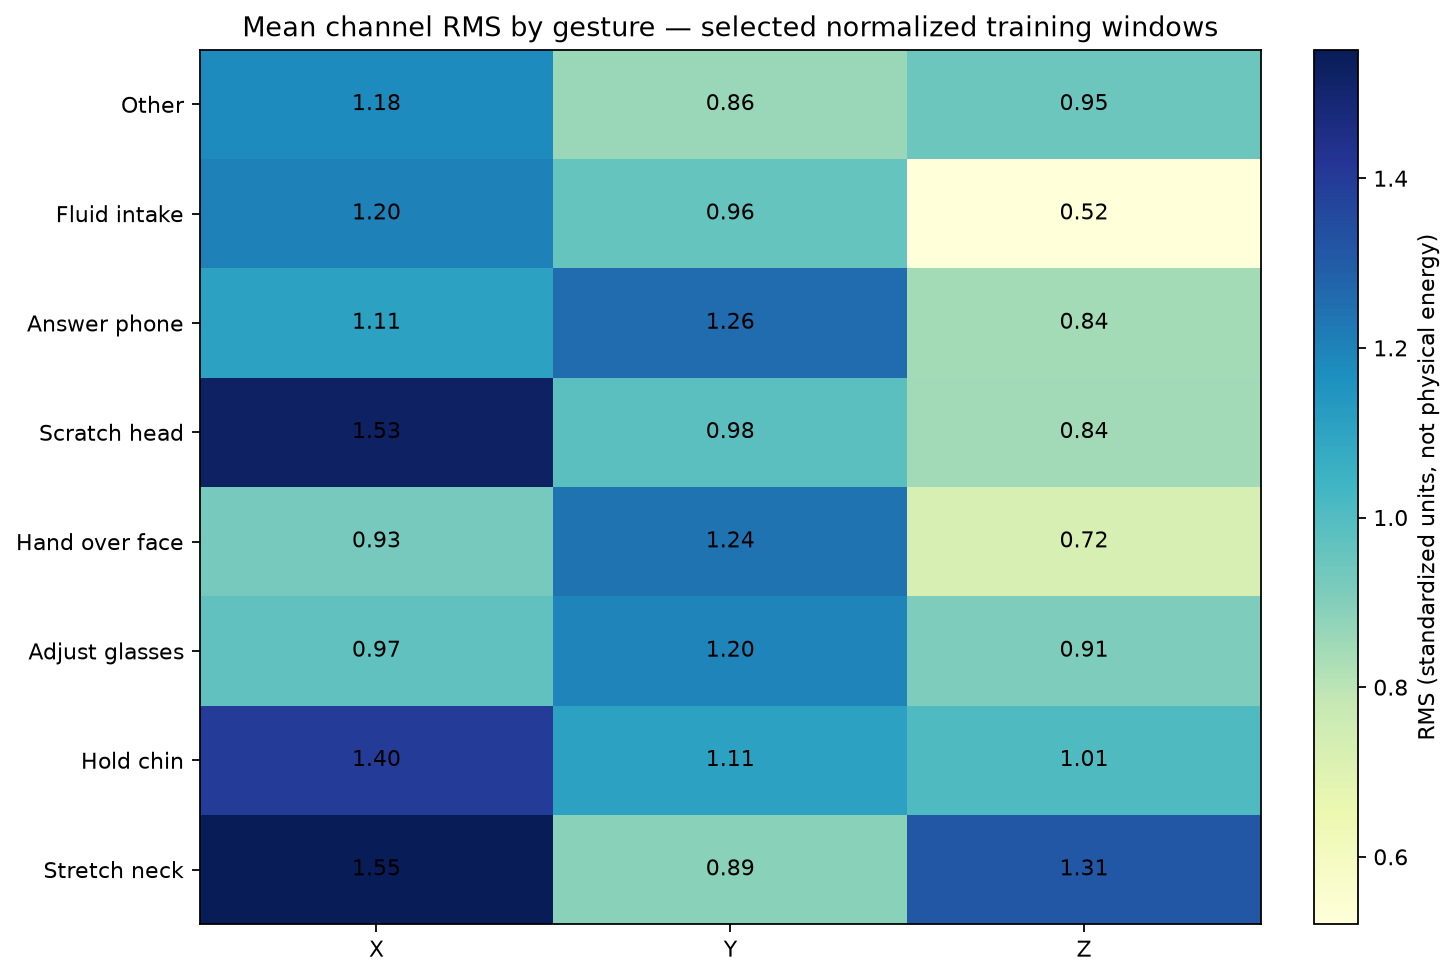

In [18]:
path = channel_rms(pool,METADATA,OUTPUT)
display(Image(filename=str(path)))

## 15. Time–Frequency View — STFT

STFT trục X của cùng mẫu đã chọn, NFFT=64, overlap=48. Tần số cycles/sample không đòi hỏi xác minh tần số vật lý. Hình này chỉ là EDA, chưa thay phép adapter/FFT của model đang deploy.

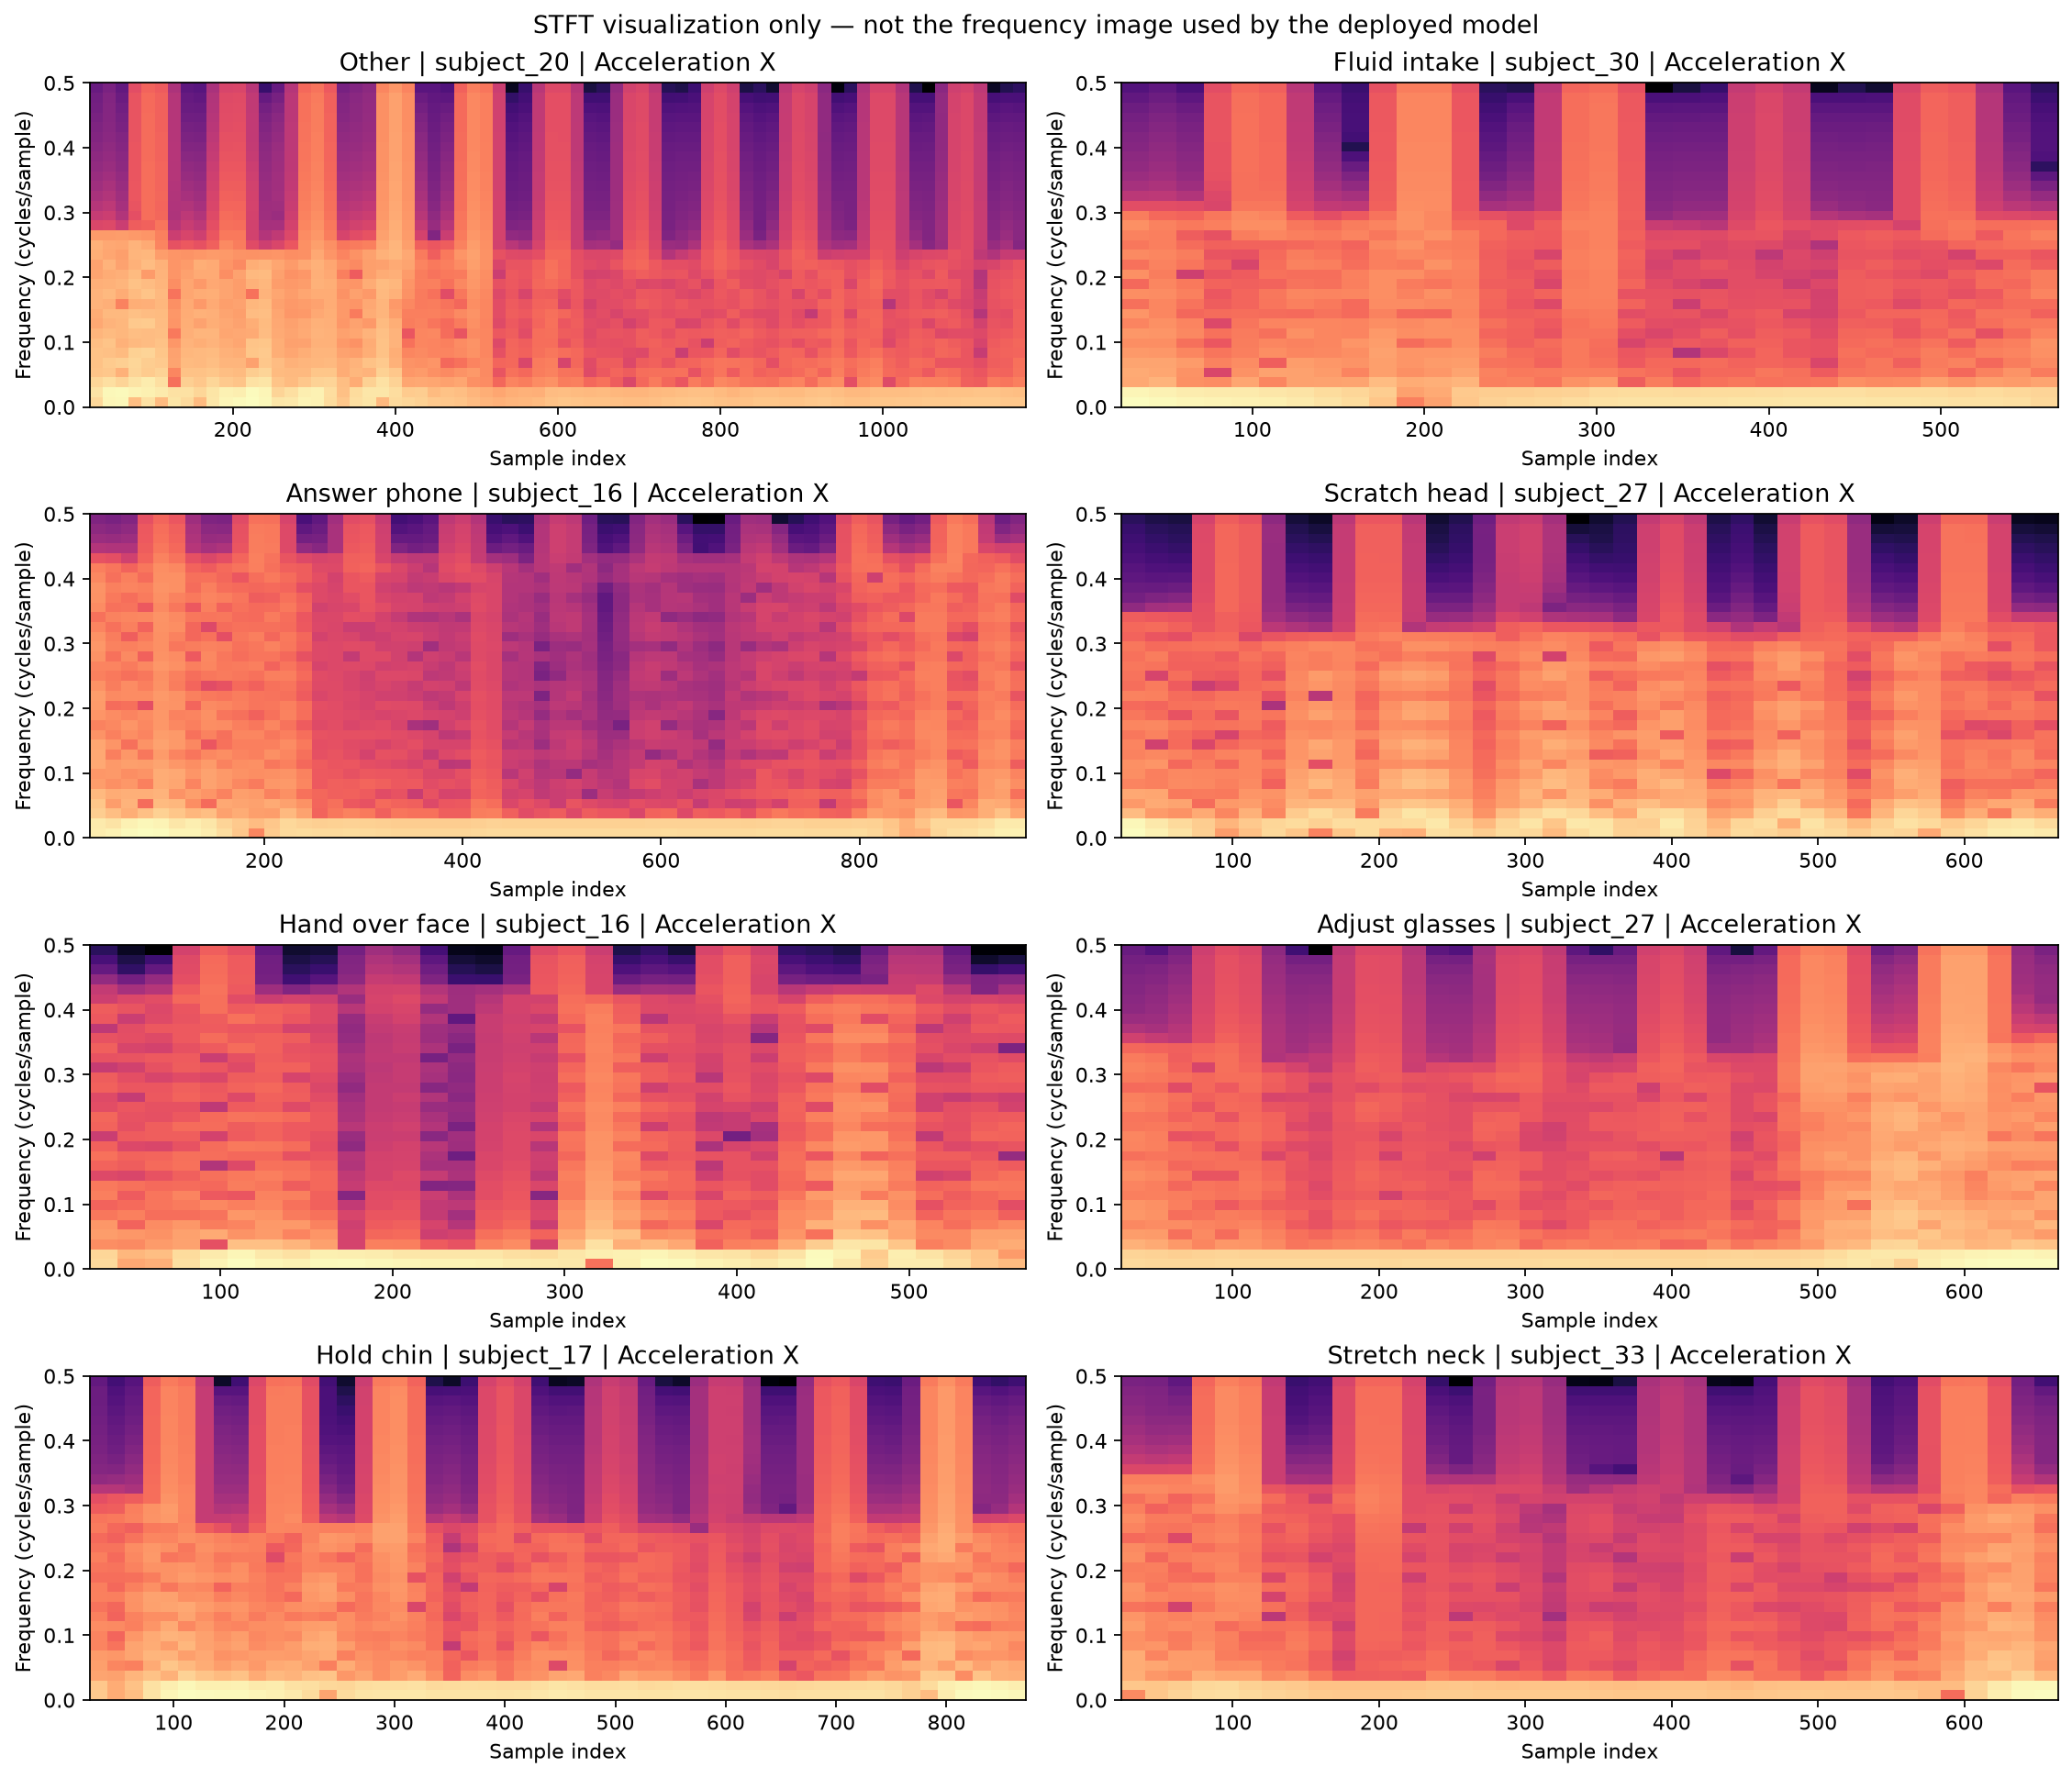

In [19]:
path = time_frequency(pool,METADATA,OUTPUT)
display(Image(filename=str(path)))

## 16. Summary — kết luận từ dữ liệu

Mục dưới tính trực tiếp số liệu toàn dataset và sample pool thay vì ghi tay
thống kê. Các nhận xét mô hình phải dựa trên tập chia theo người, không dựa
trên một recording đẹp.

In [20]:
counts = frame.groupby('gesture').windows.sum().sort_values(ascending=False)
print(f'{len(frame):,} recordings | {frame.subject.nunique()} subjects | {int(frame.windows.sum()):,} windows')
print(f'Majority class: {counts.index[0]} = {counts.iloc[0]/counts.sum():.2%} of windows')
print(f'Short recordings excluded from windowing: {int((frame.windows==0).sum())}')
print(f'Nonfinite X/Y/Z cells: {int(frame.nonfinite_cells.sum())}')
print(f'Figures use {len(pool_manifest)} seeded training recordings from distinct subjects per gesture.')

5,345 recordings | 50 subjects | 68,854 windows
Majority class: other = 75.50% of windows
Short recordings excluded from windowing: 9
Nonfinite X/Y/Z cells: 0
Figures use 96 seeded training recordings from distinct subjects per gesture.


### Ý nghĩa đối với TF-C + DINOv3

- Tỷ lệ lớp phải được tính trên dữ liệu thật; không đổi nhãn để làm cân bằng.
- Với phân bố lệch lớp, so sánh Cross Entropy, CB Cross Entropy, CB Focal; dùng
  cùng sampler, tập chia và seed. Chọn cấu hình bằng macro F1 validation.
- CB weighting bằng nhau nếu chỉ lấy cùng số cửa sổ mỗi lớp. Vì vậy nên chạy
  đánh giá loss trên train đầy đủ hoặc tập con giữ phân bố tự nhiên.
- Báo cáo cả macro F1, balanced accuracy, recall từng lớp; accuracy có thể tăng
  trong khi một số cử chỉ hiếm kém đi.
- Không tuyên bố đã thu thập dữ liệu private hoặc đã dùng pretrained DINOv3.

**Bàn giao theo mẫu:** gửi link Kaggle Dataset **và** link Notebook đã Save
Version/Run All, có outputs, đặt Public. Các PNG nằm trong output notebook để tải xuống.

Nguồn: [TF-C](https://github.com/mims-harvard/TFC-pretraining),
[DINOv3](https://github.com/facebookresearch/dinov3),
[Class-Balanced Loss](https://arxiv.org/abs/1901.05555).